In [1]:
# %matplotlib ipympl

In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib import pyplot as plt
from tqdm import tqdm

import ppg_funcs
from config import Config as c

In [3]:
df_subjects = ppg_funcs.load_subjects()
# df_subjects

In [4]:
df_points = ppg_funcs.load_points()
# df_points

15it [00:02,  5.97it/s]/tmp/ipykernel_95752/172987031.py:22: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  fig_s, axes_s = plt.subplots(nrows=1, ncols=1, figsize=(15, 5))
34it [00:03,  9.54it/s]


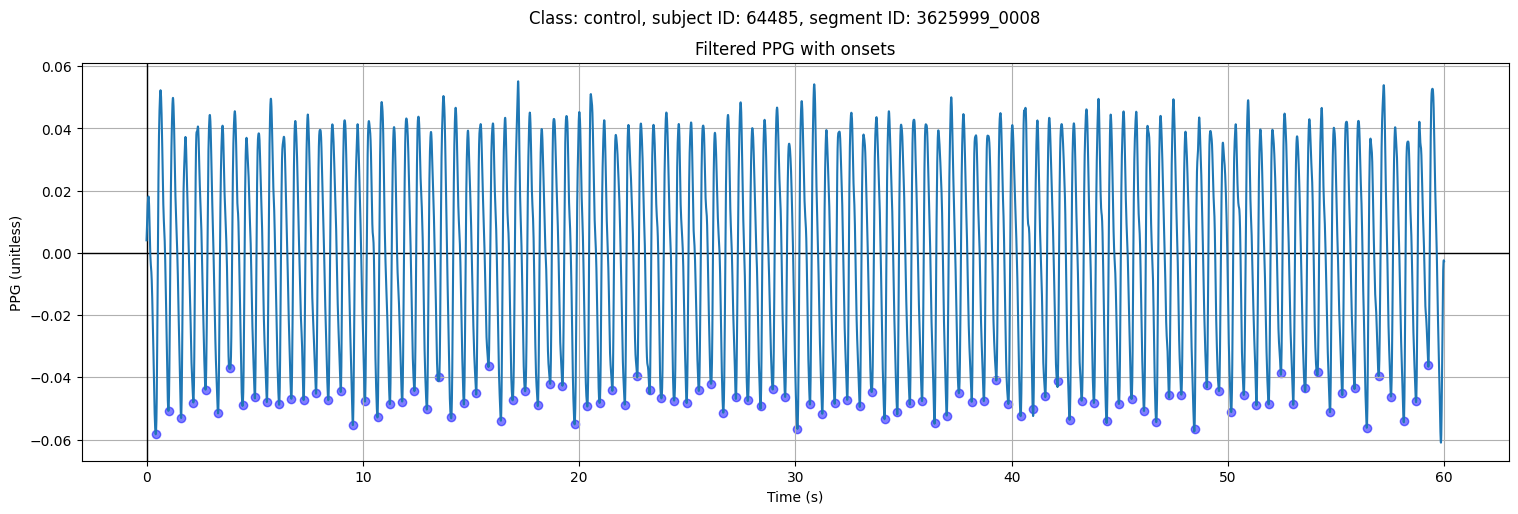

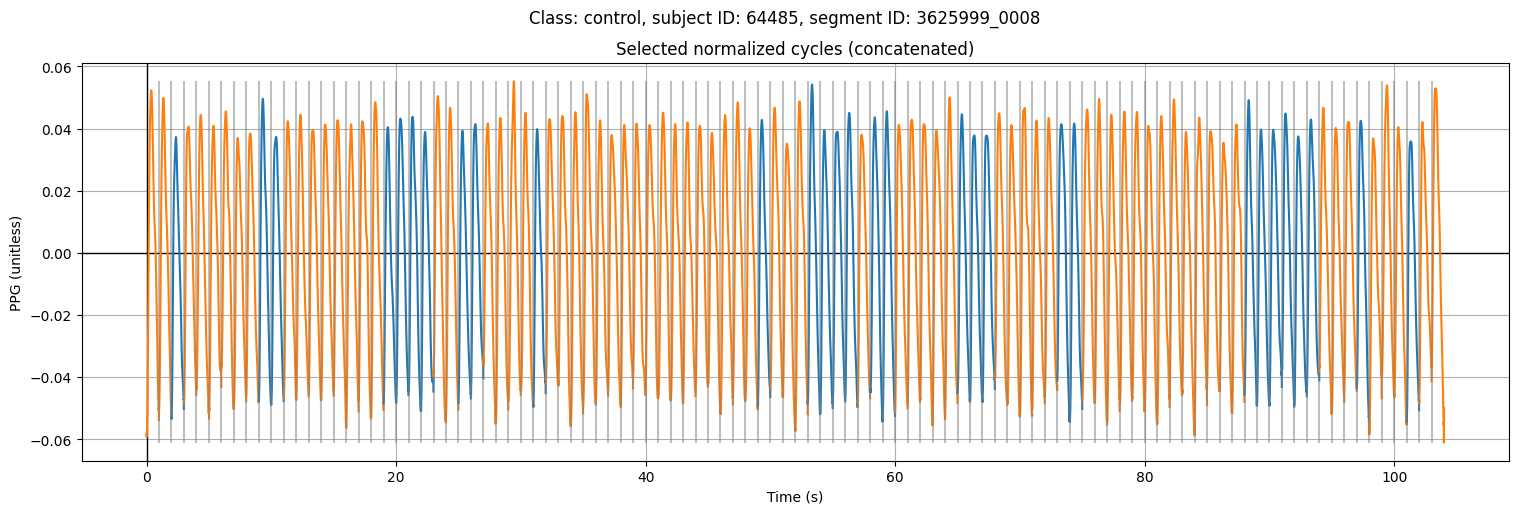

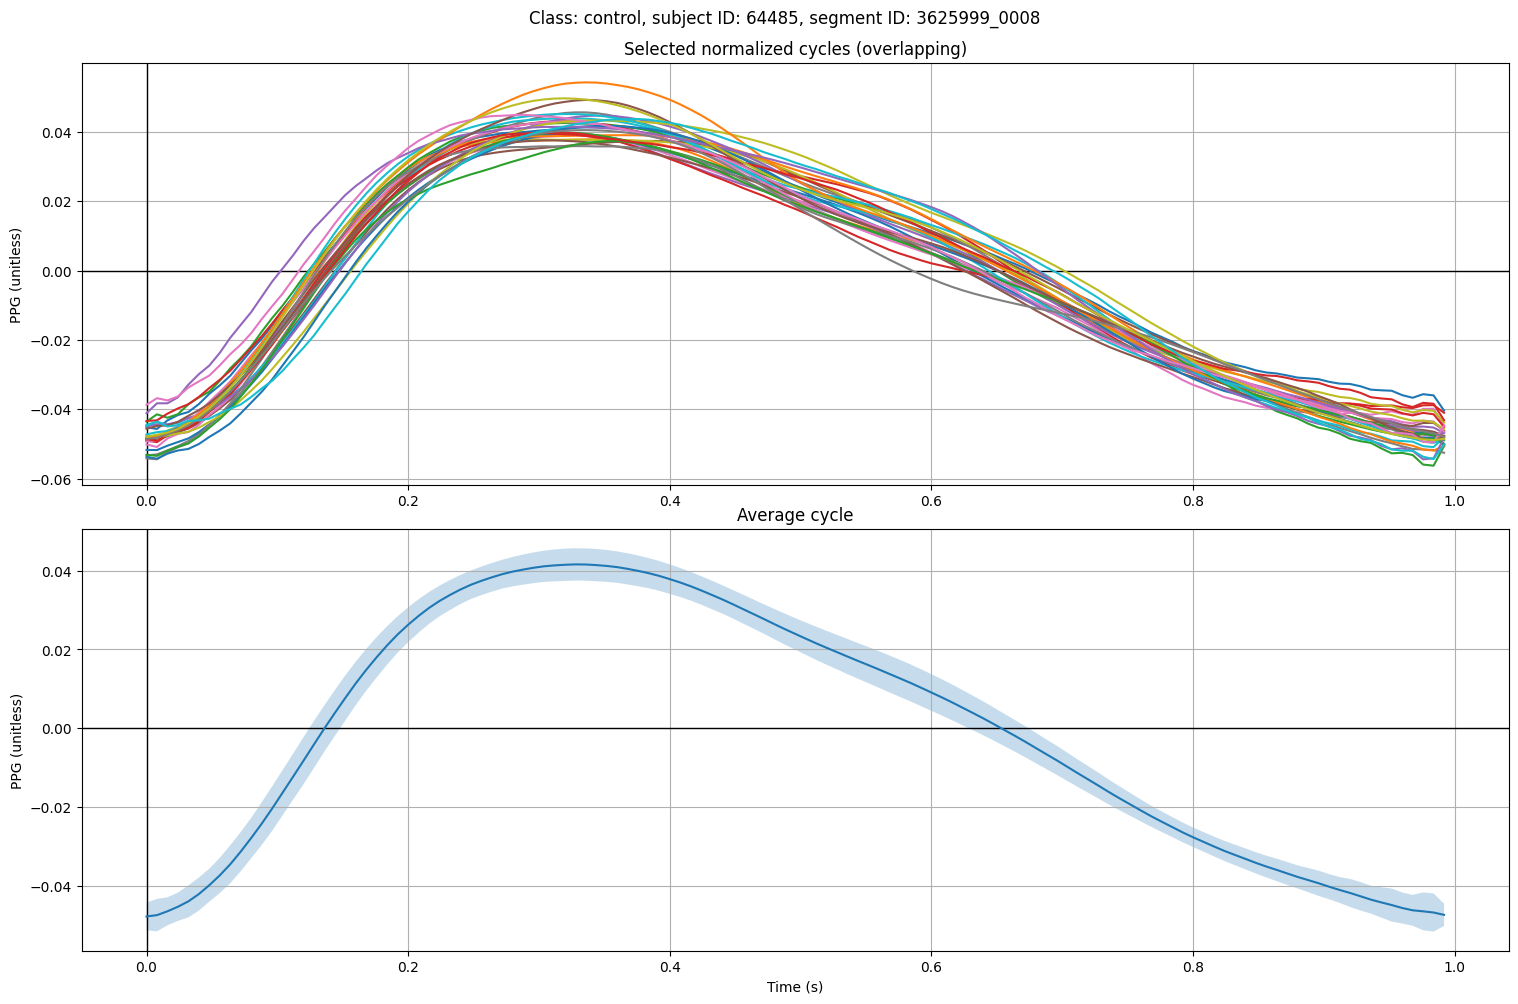

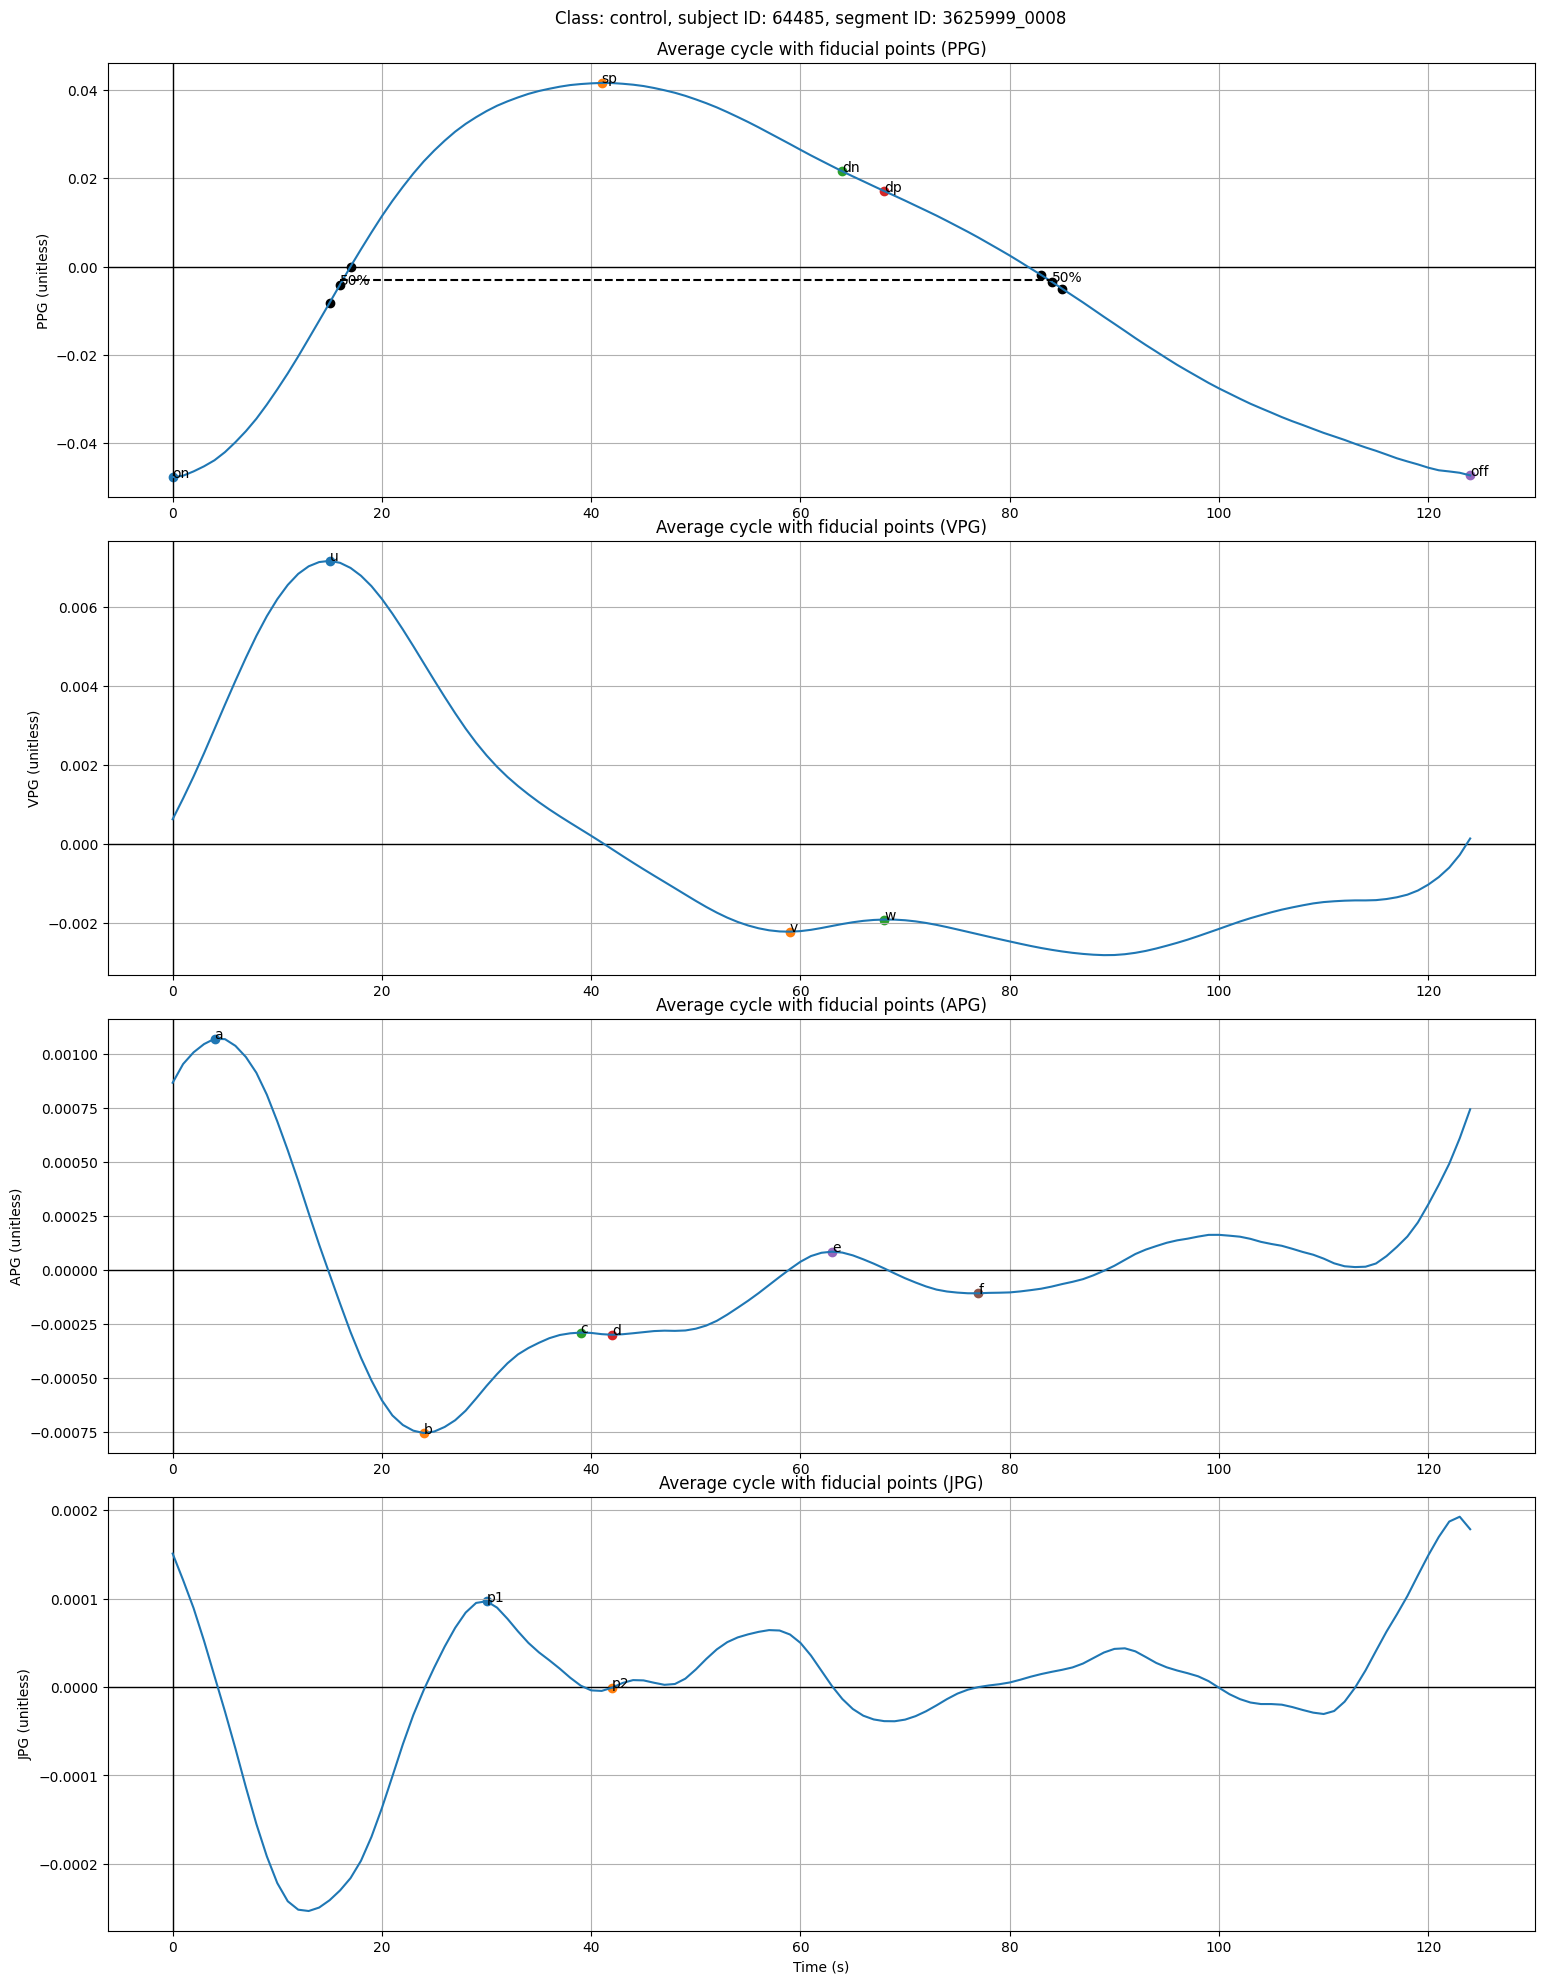

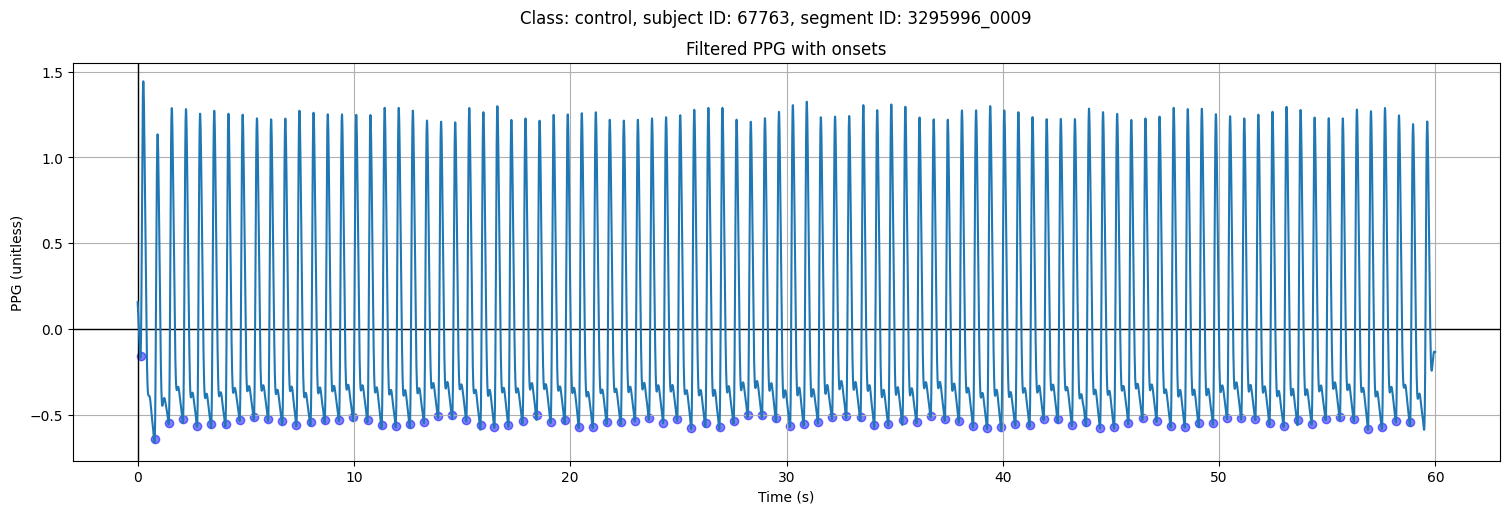

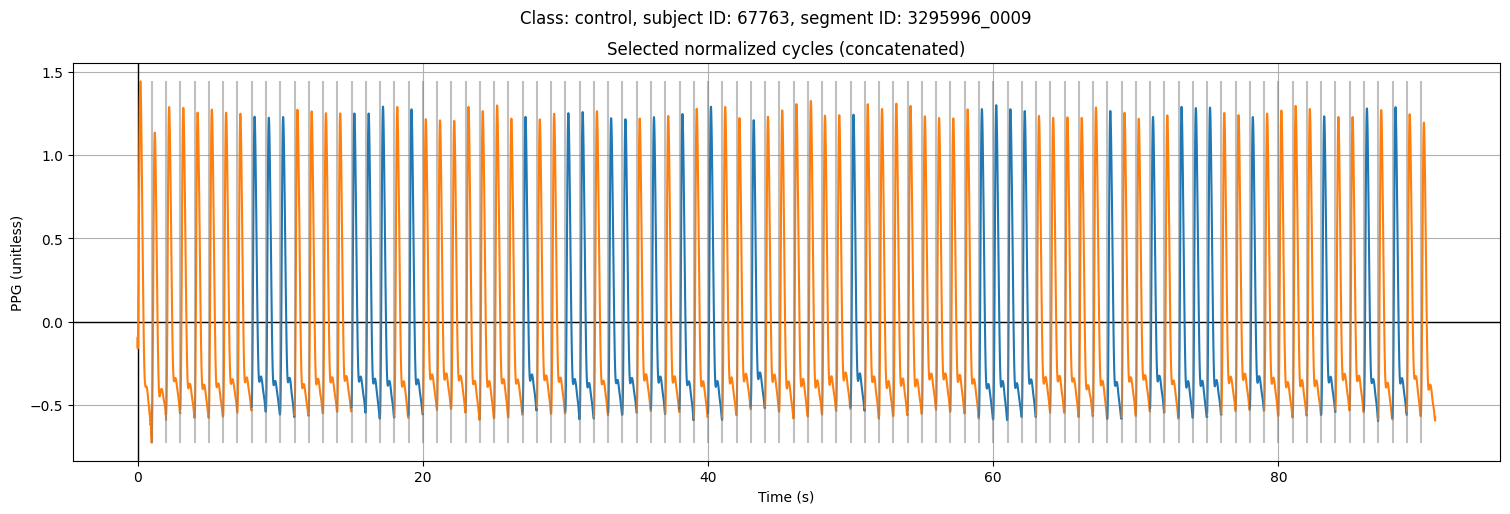

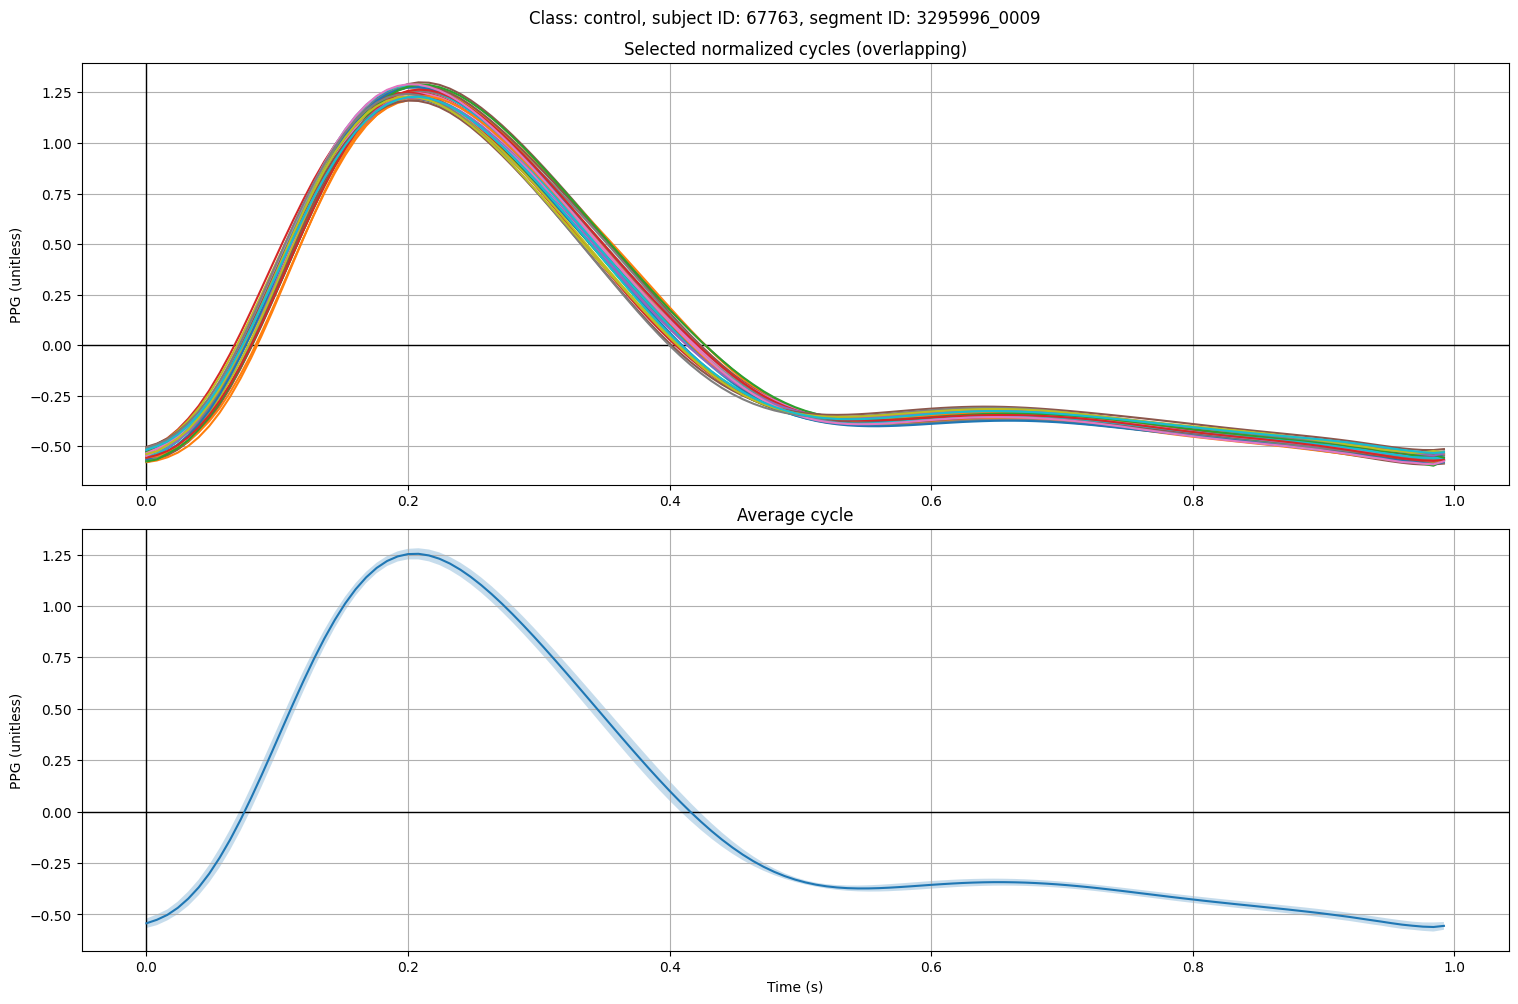

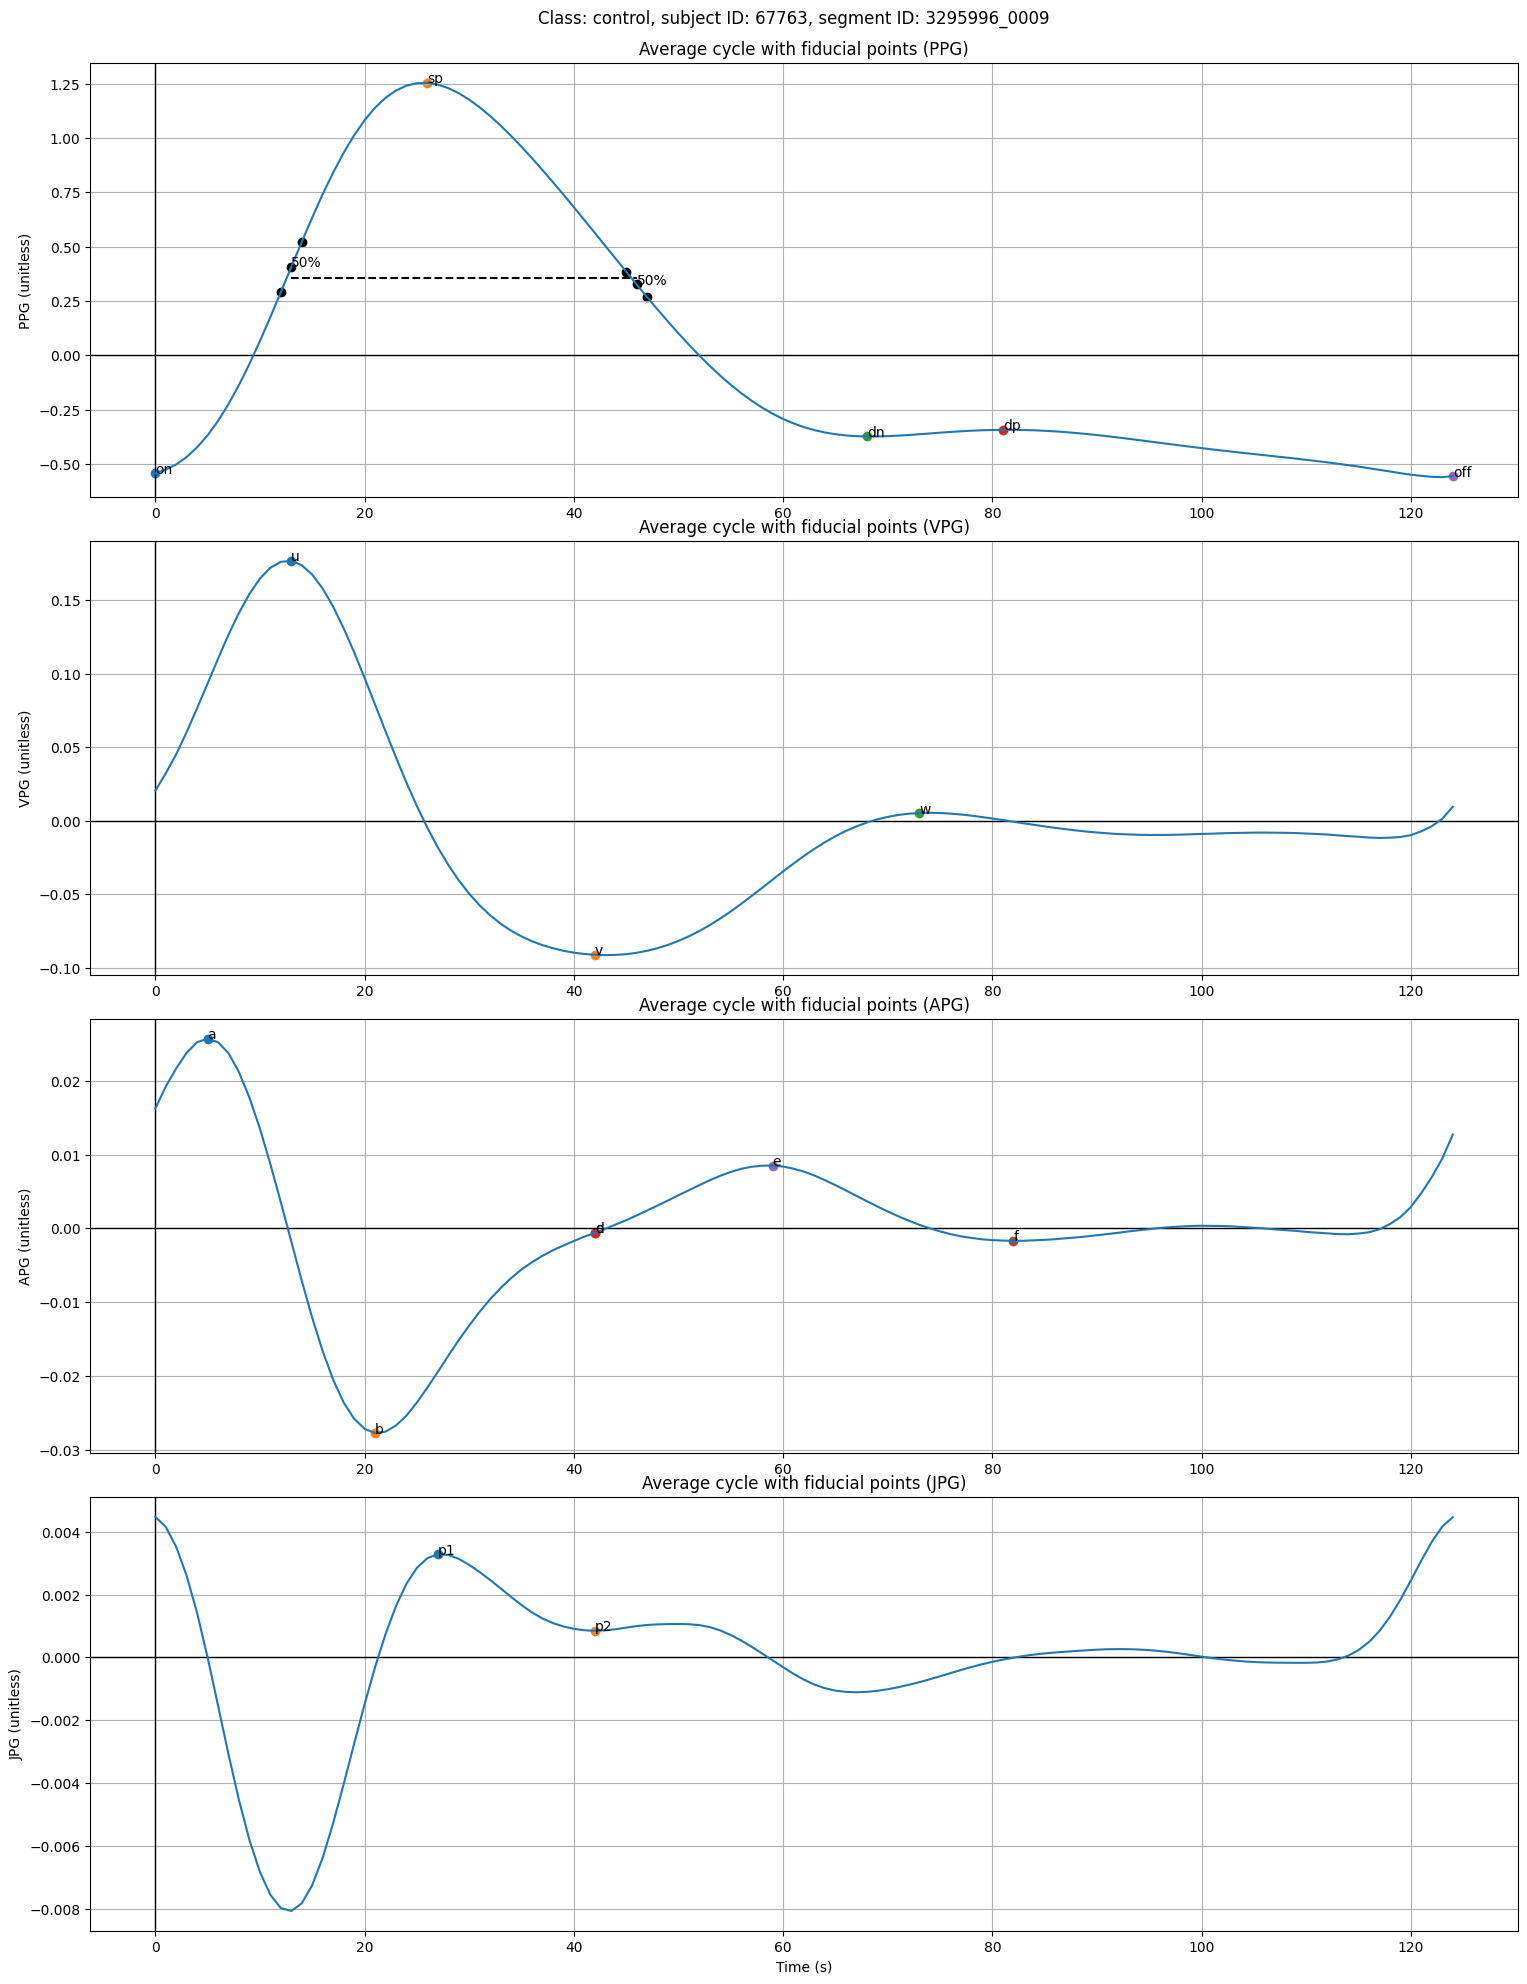

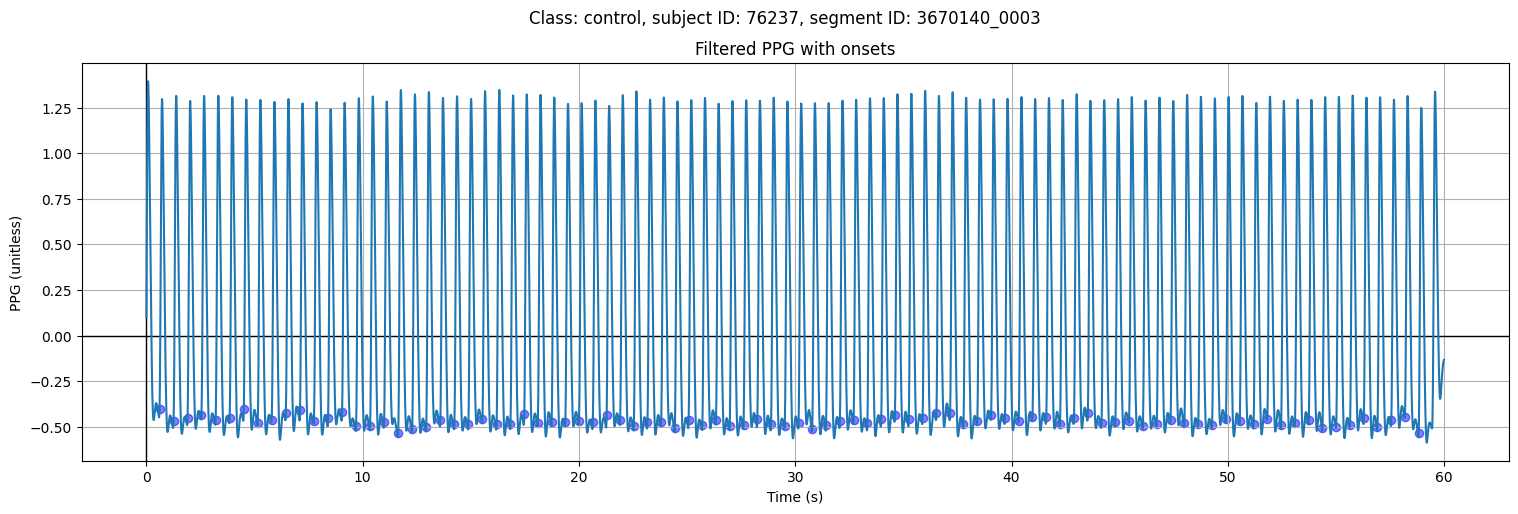

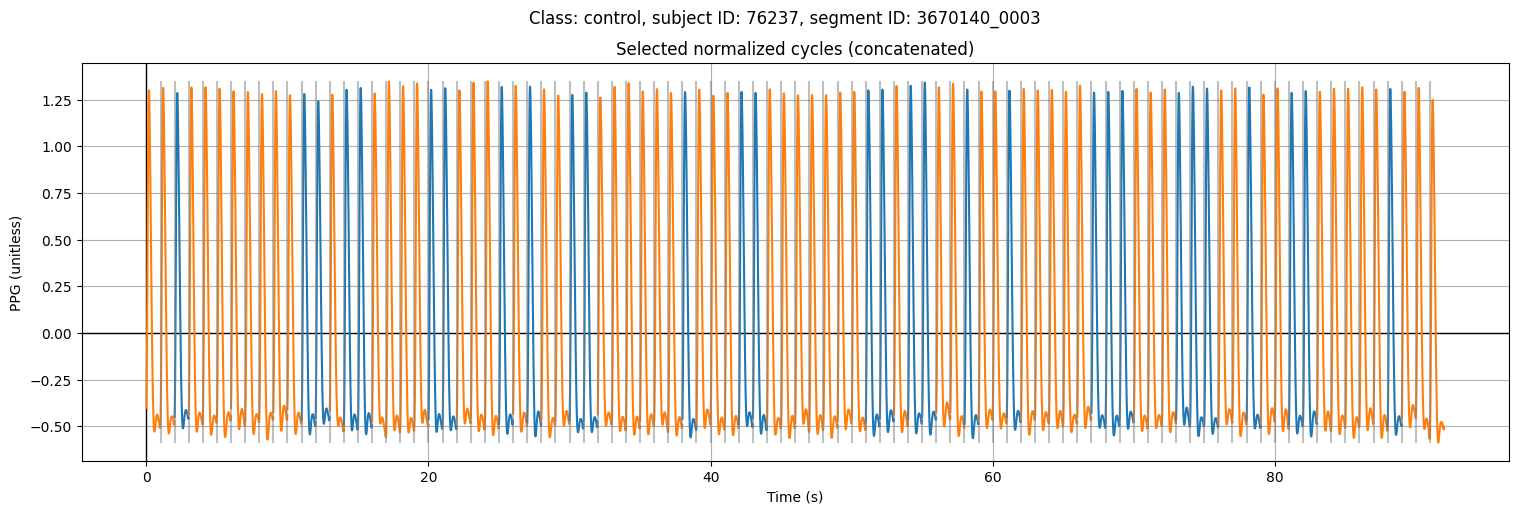

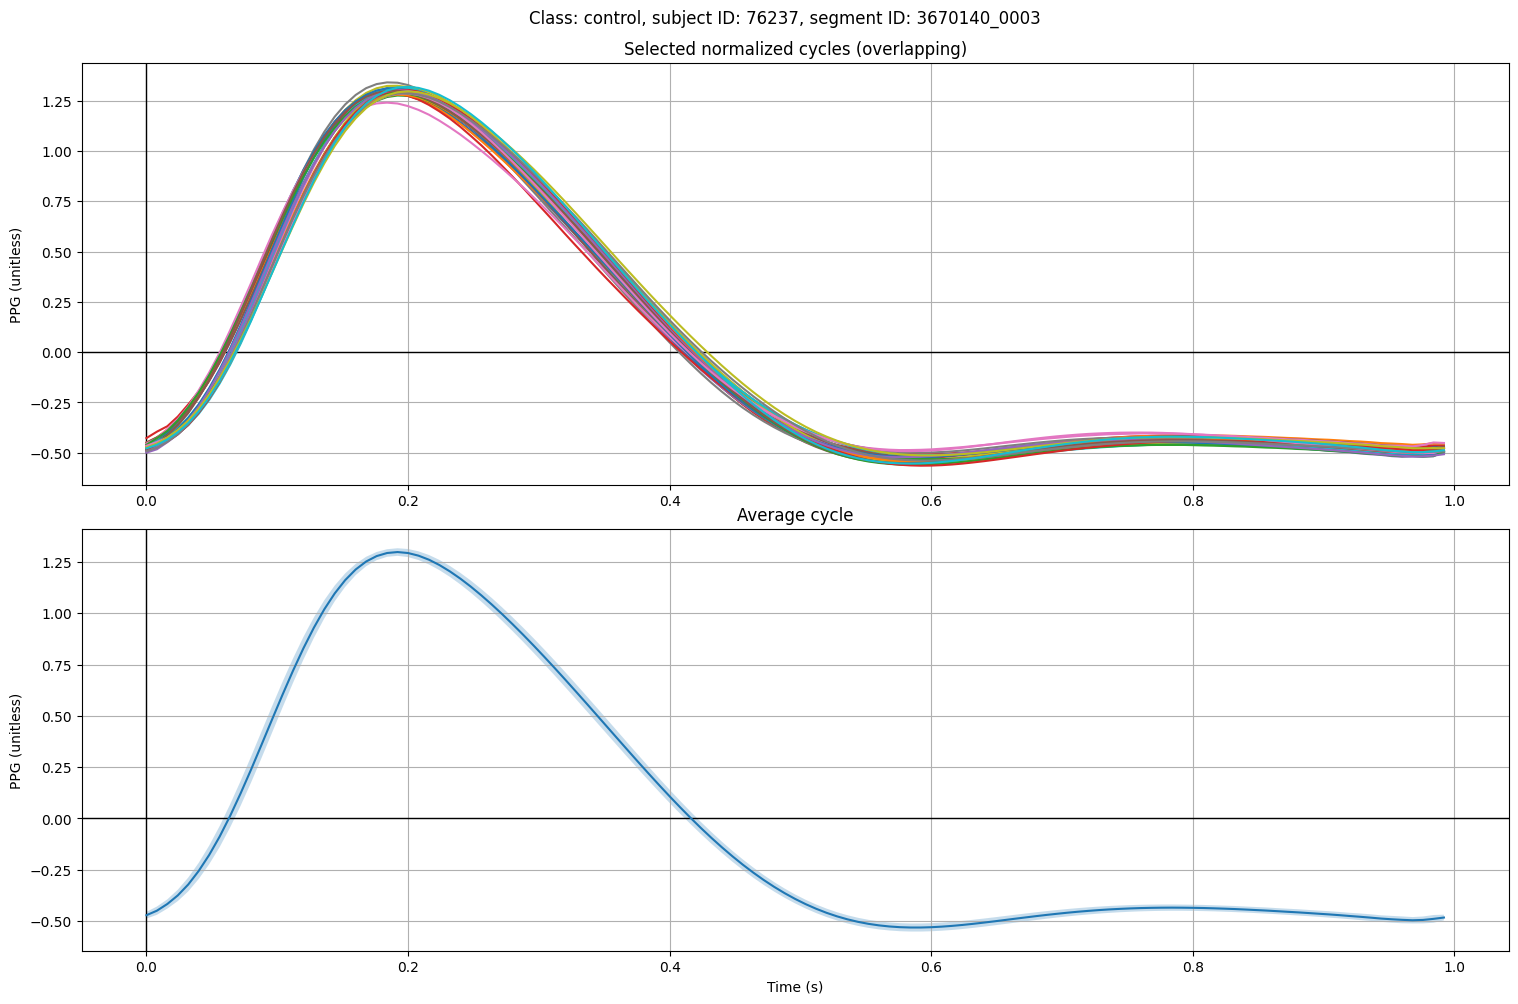

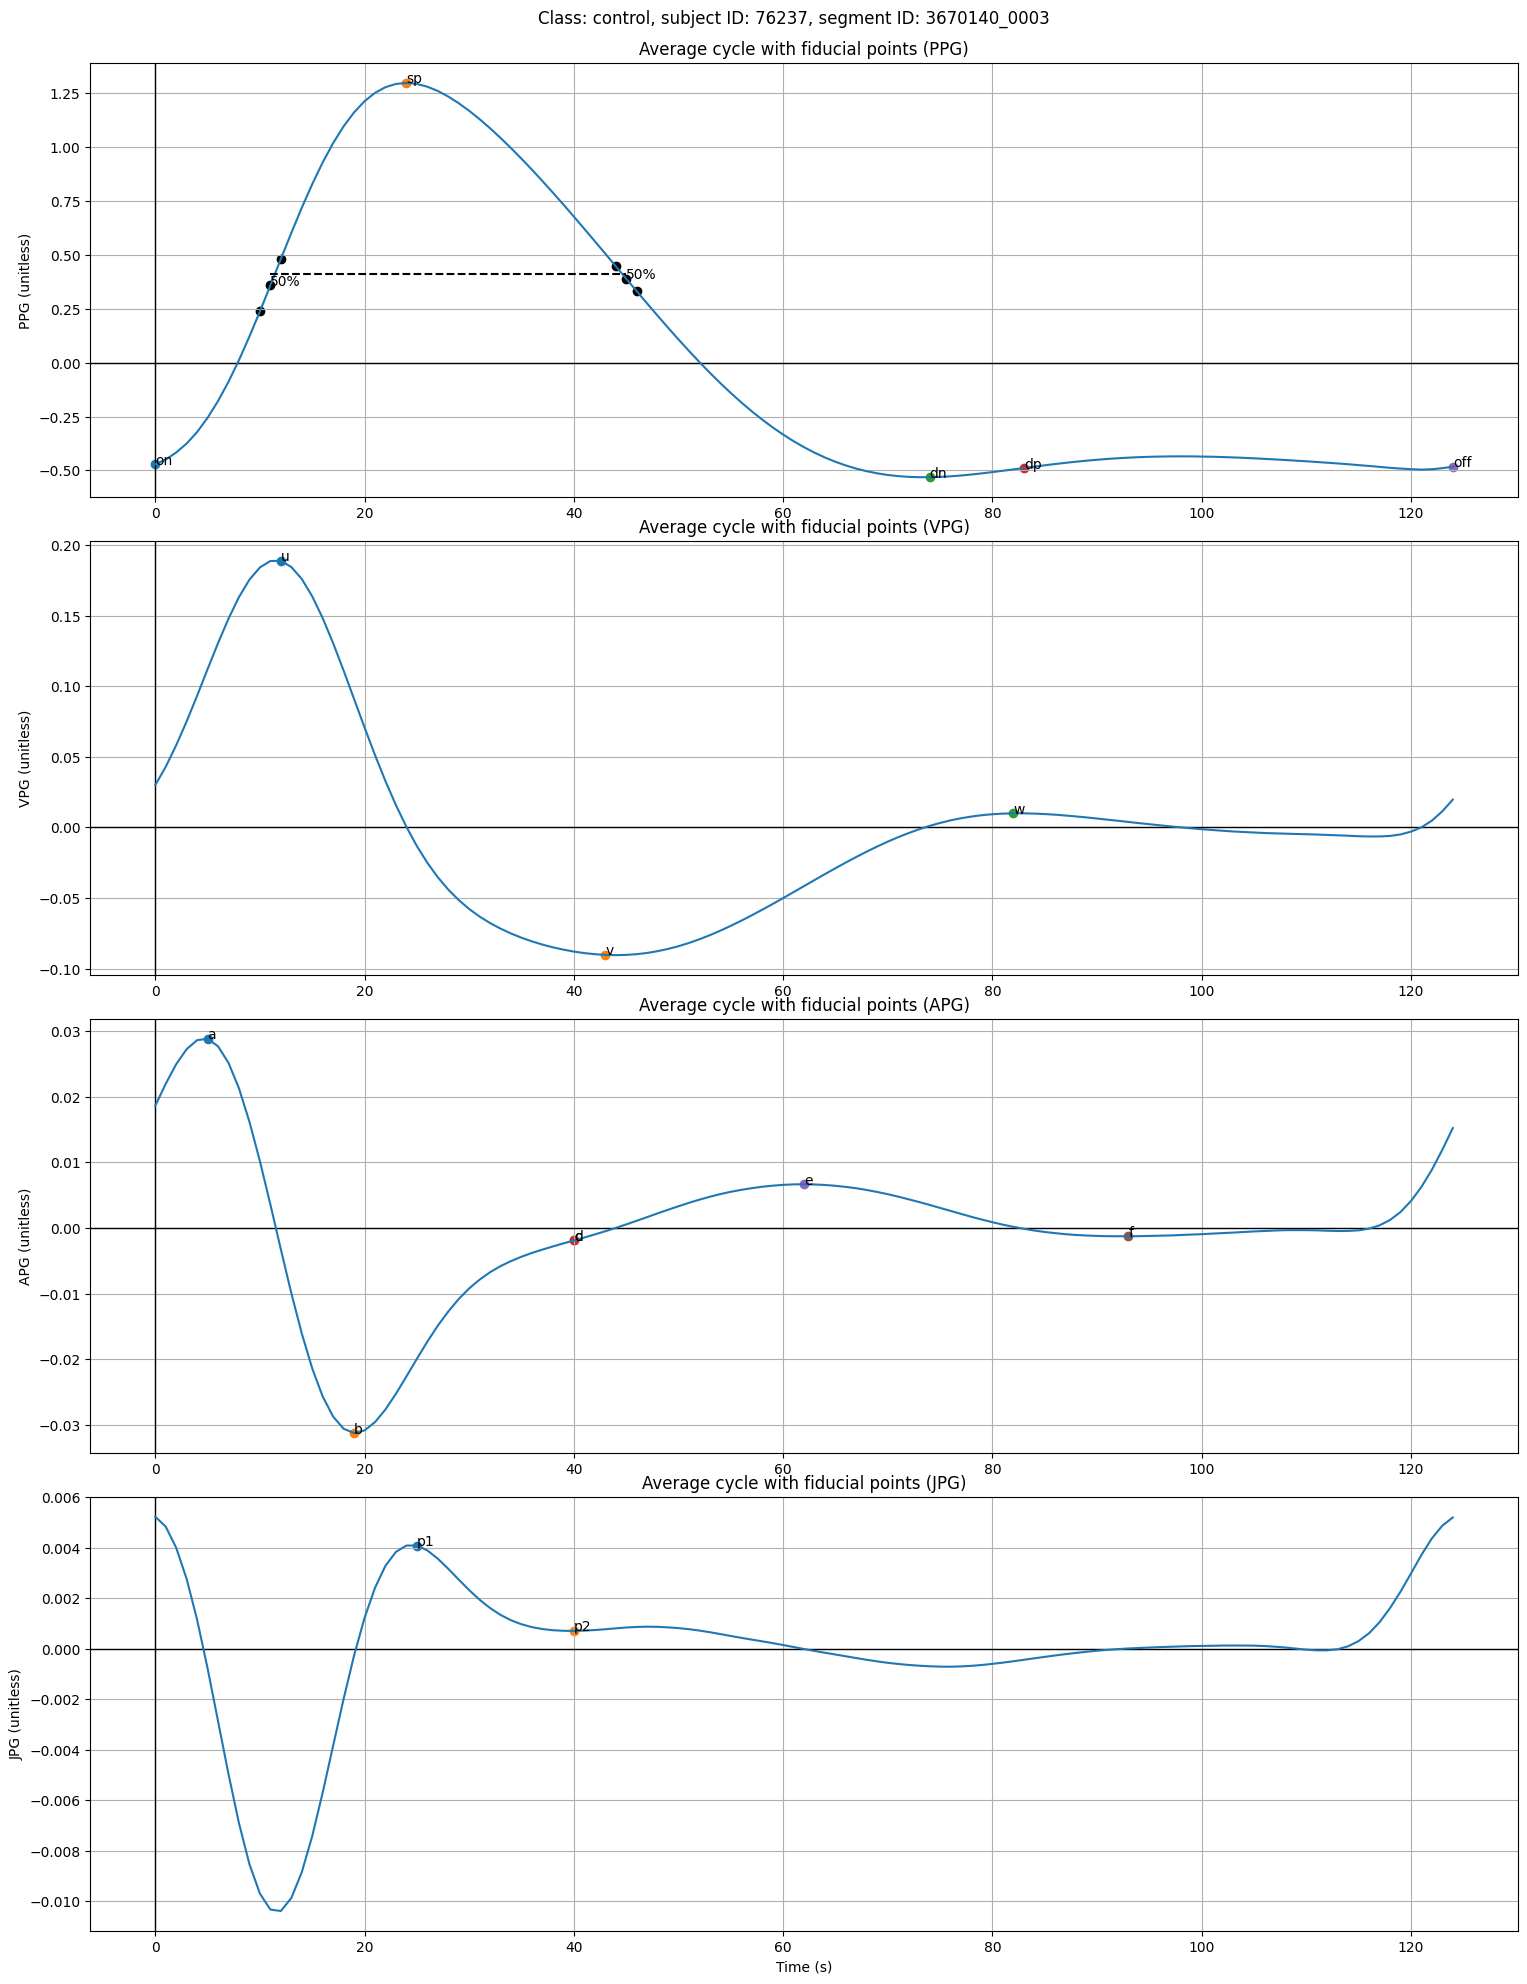

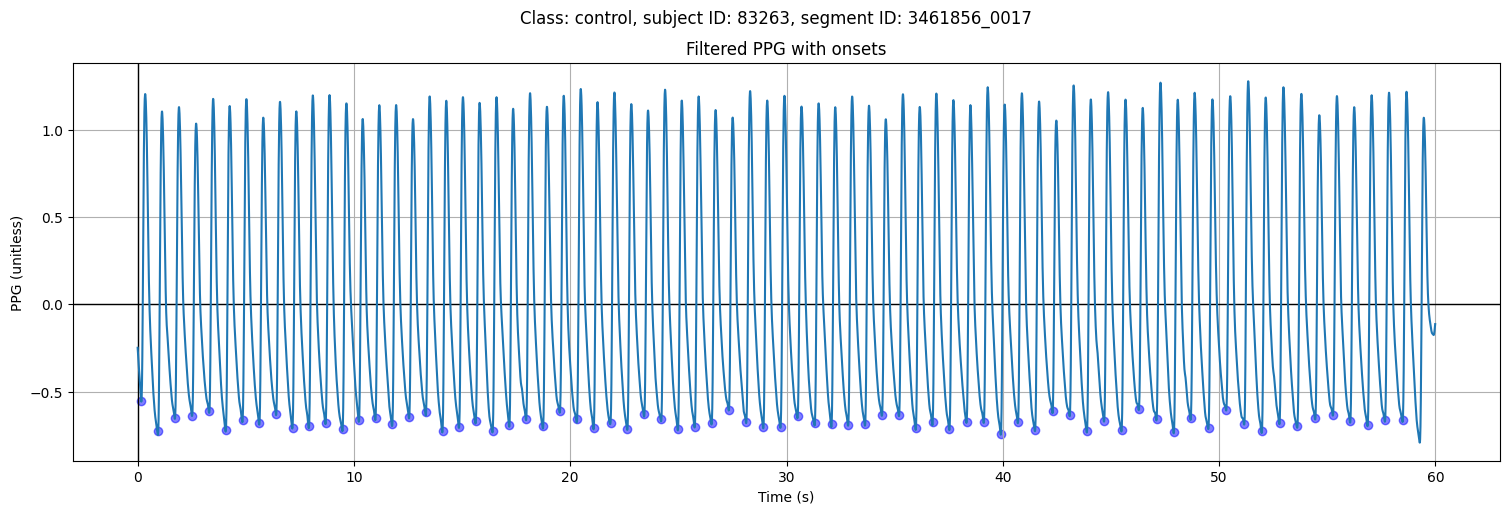

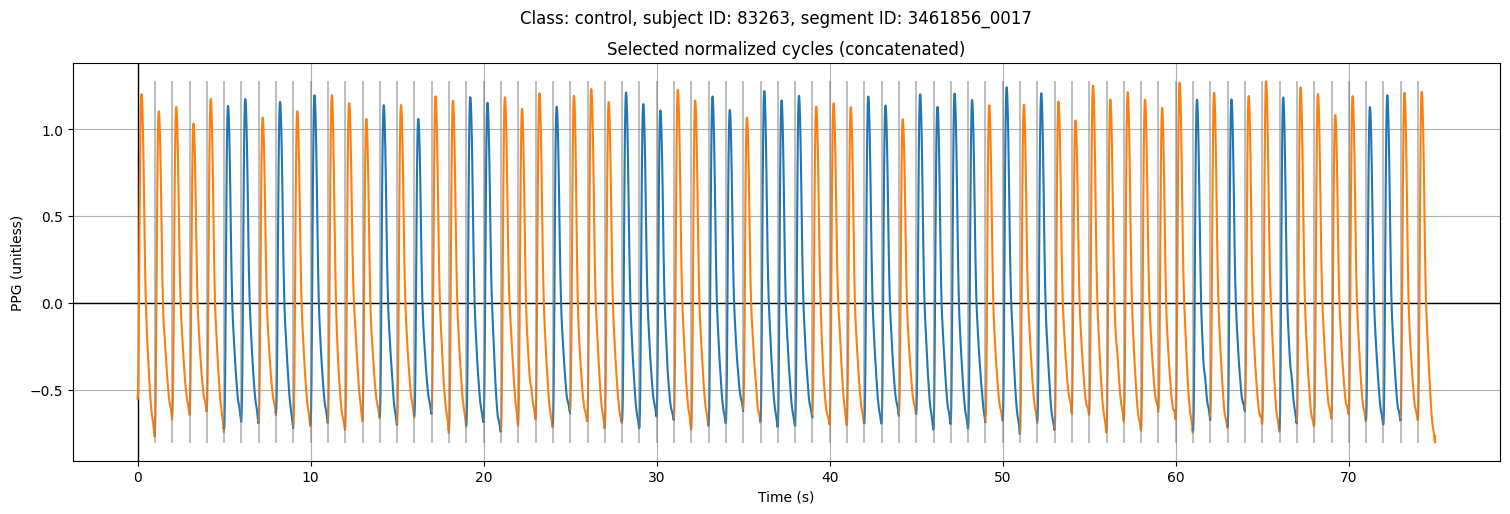

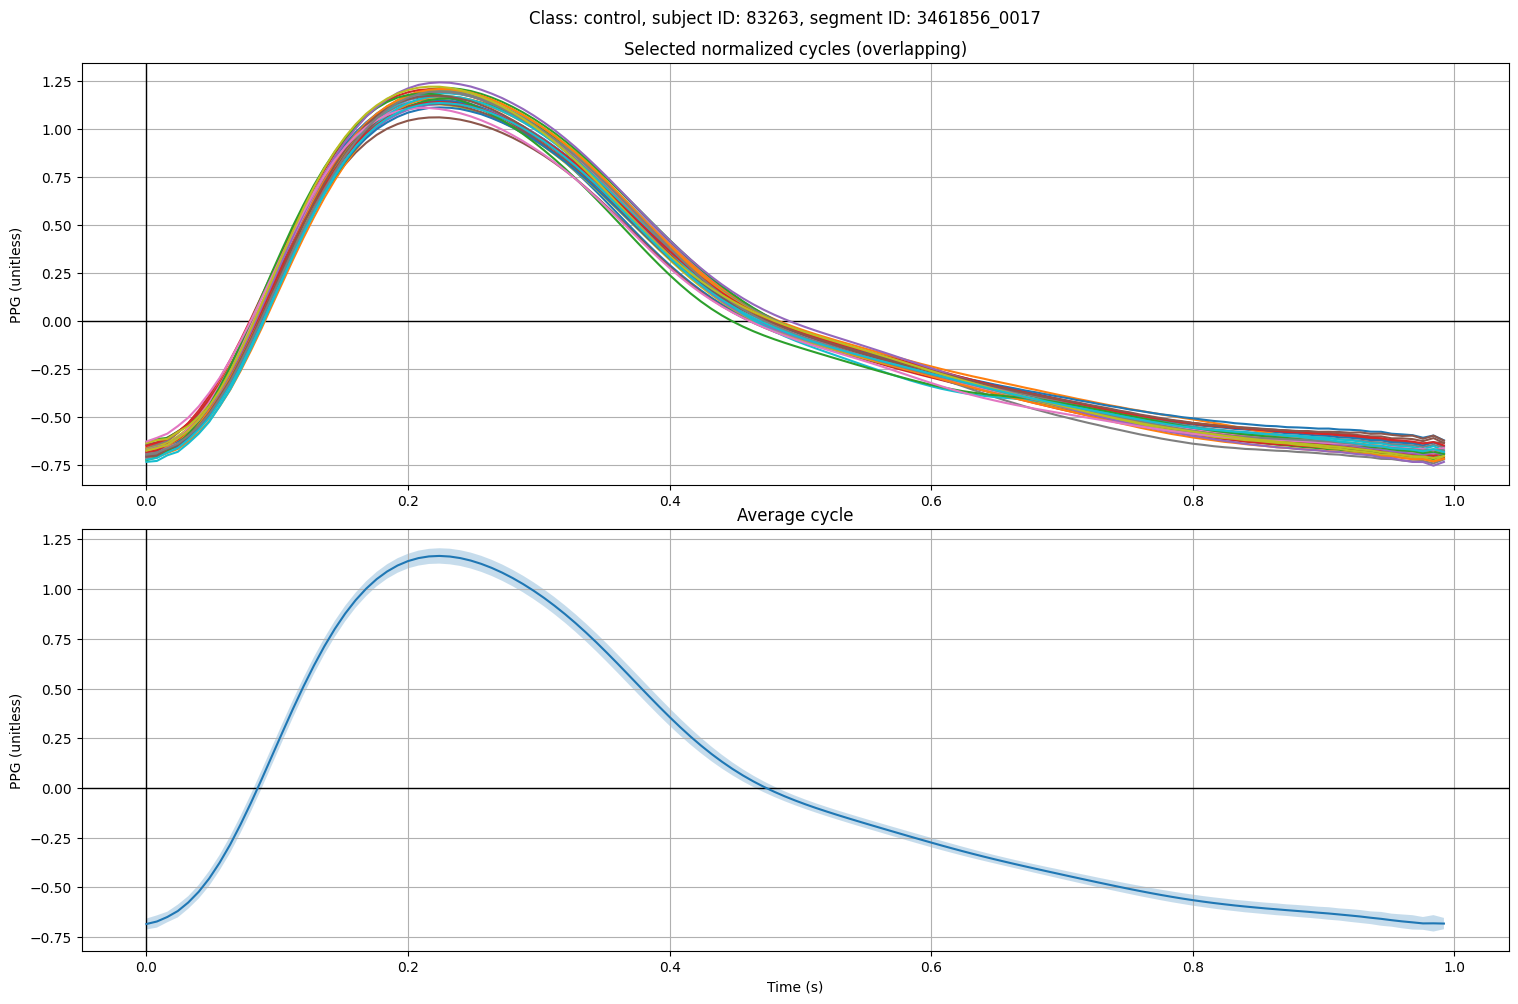

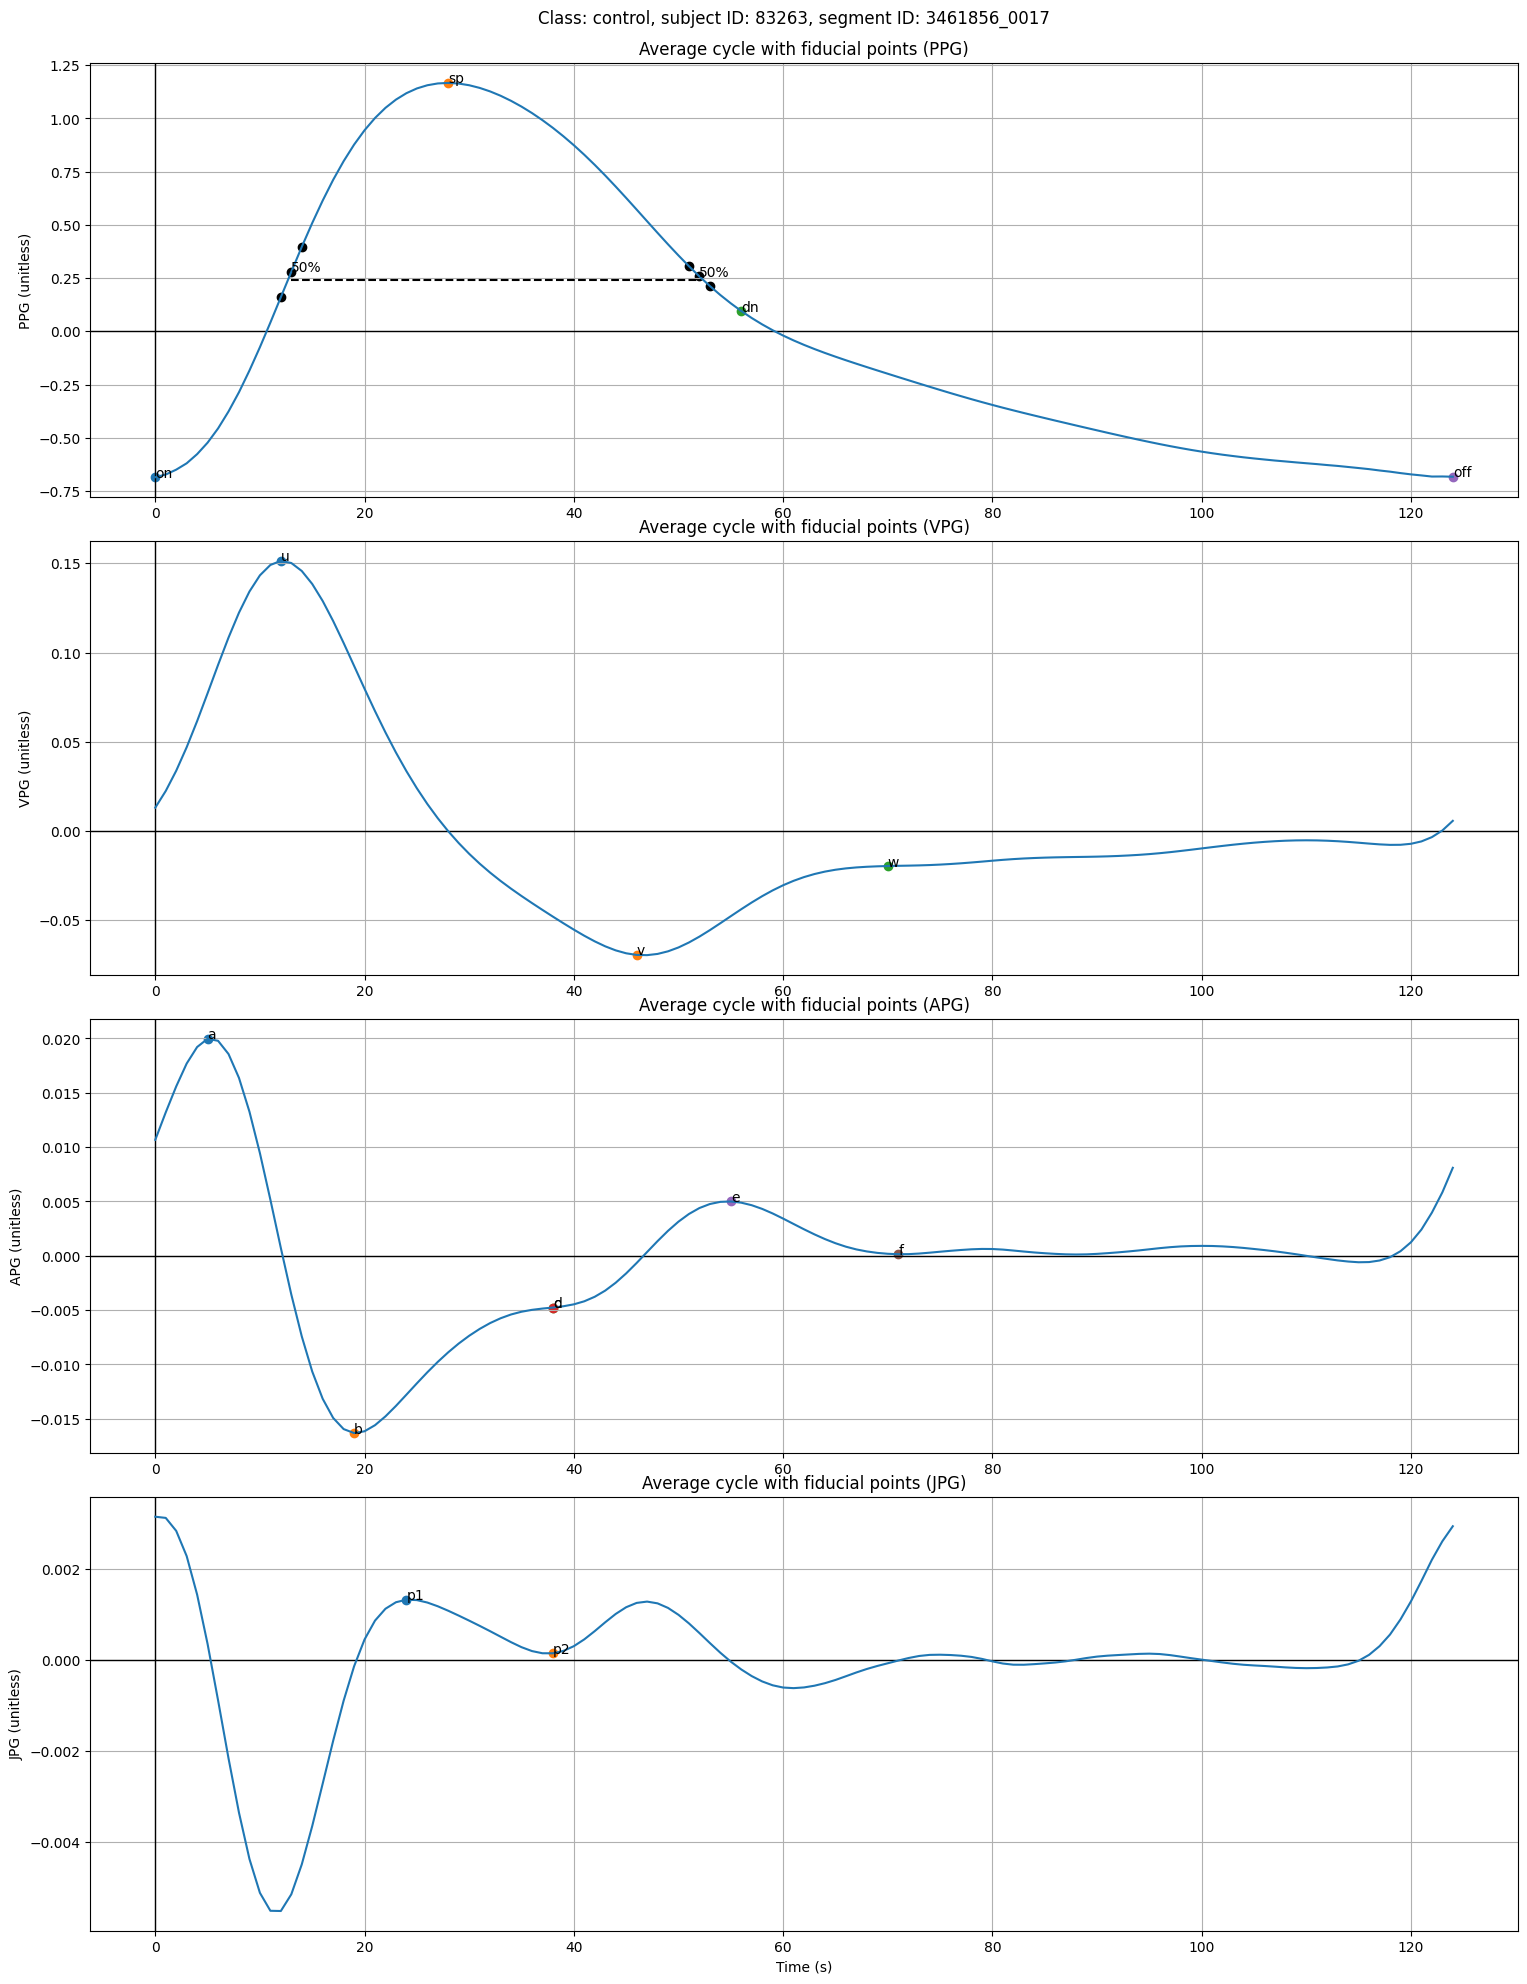

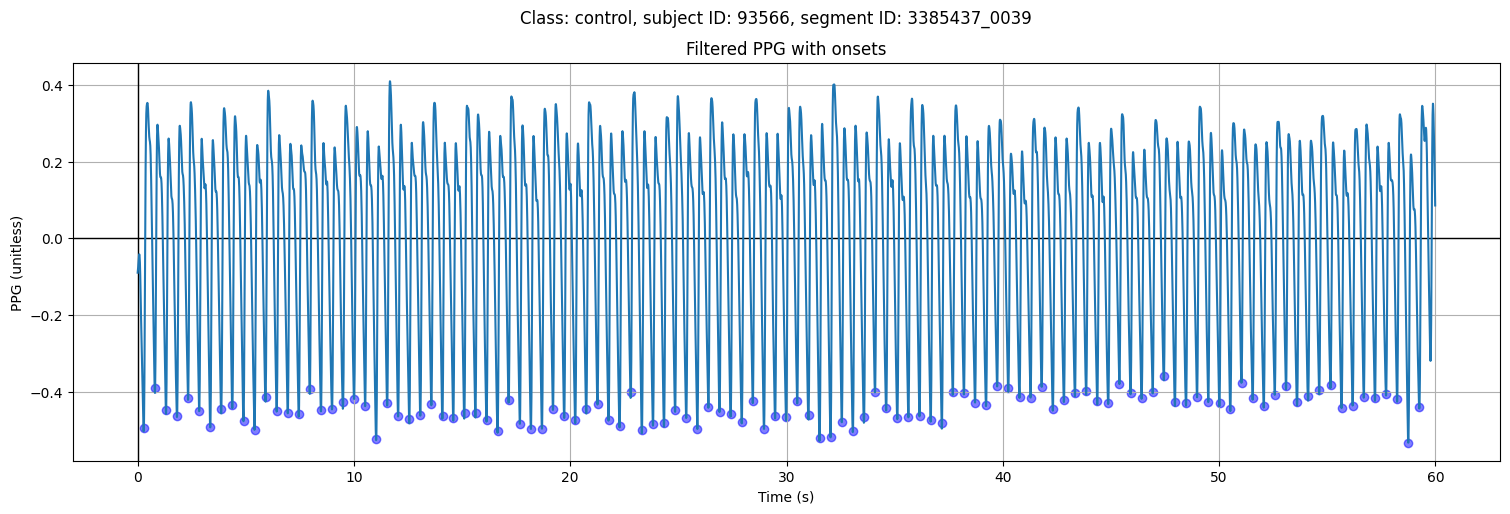

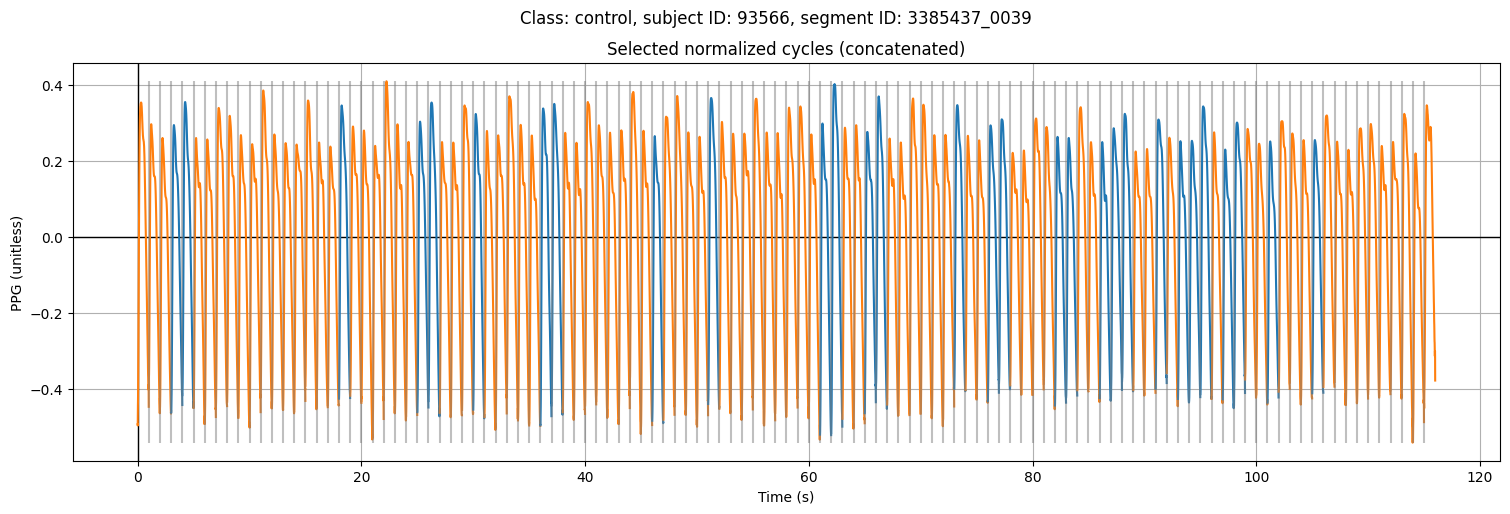

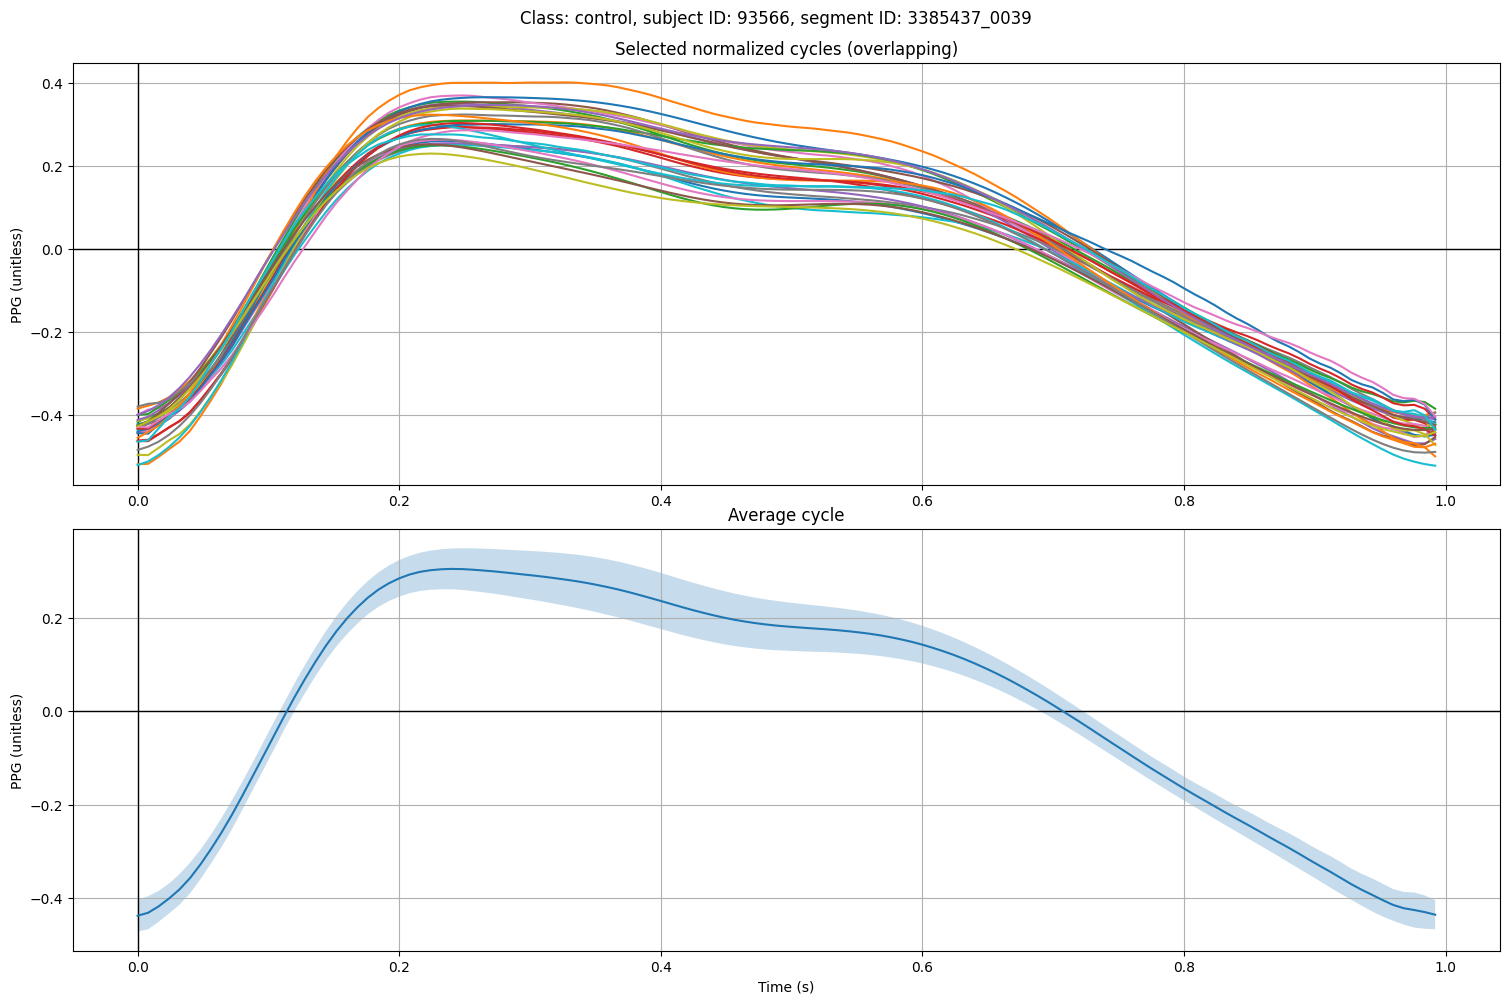

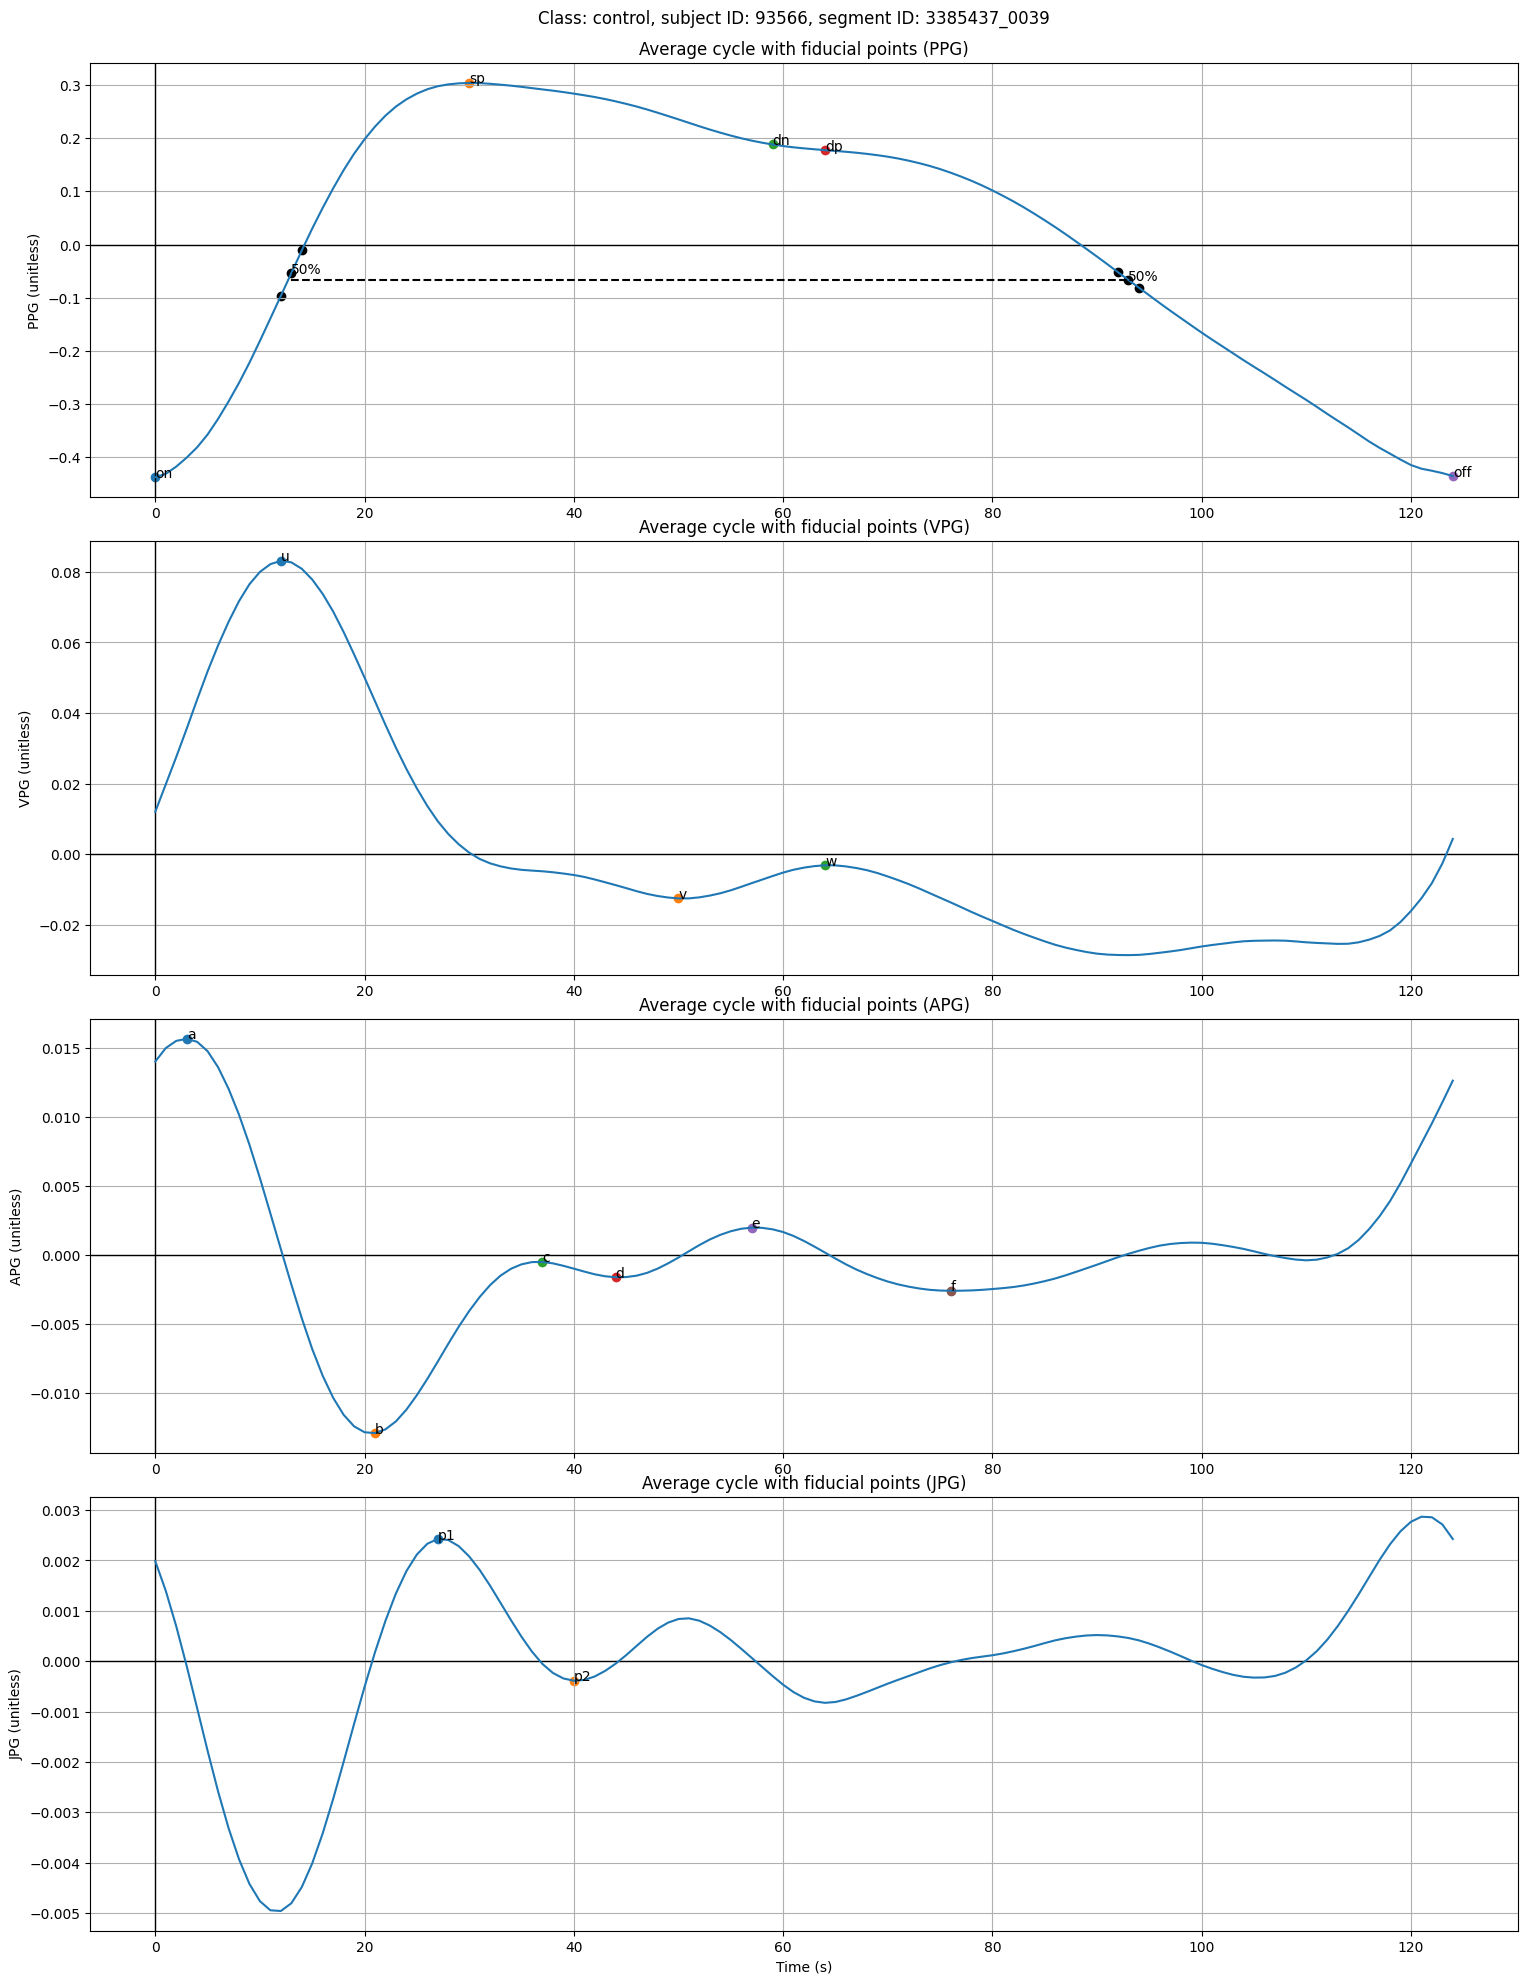

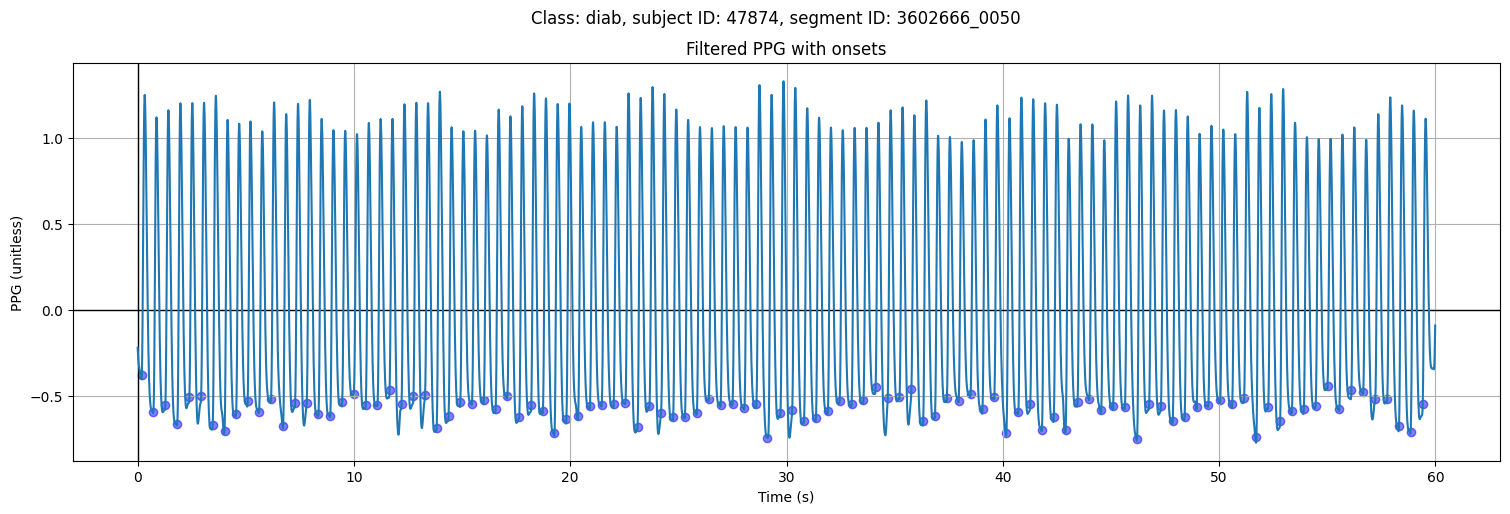

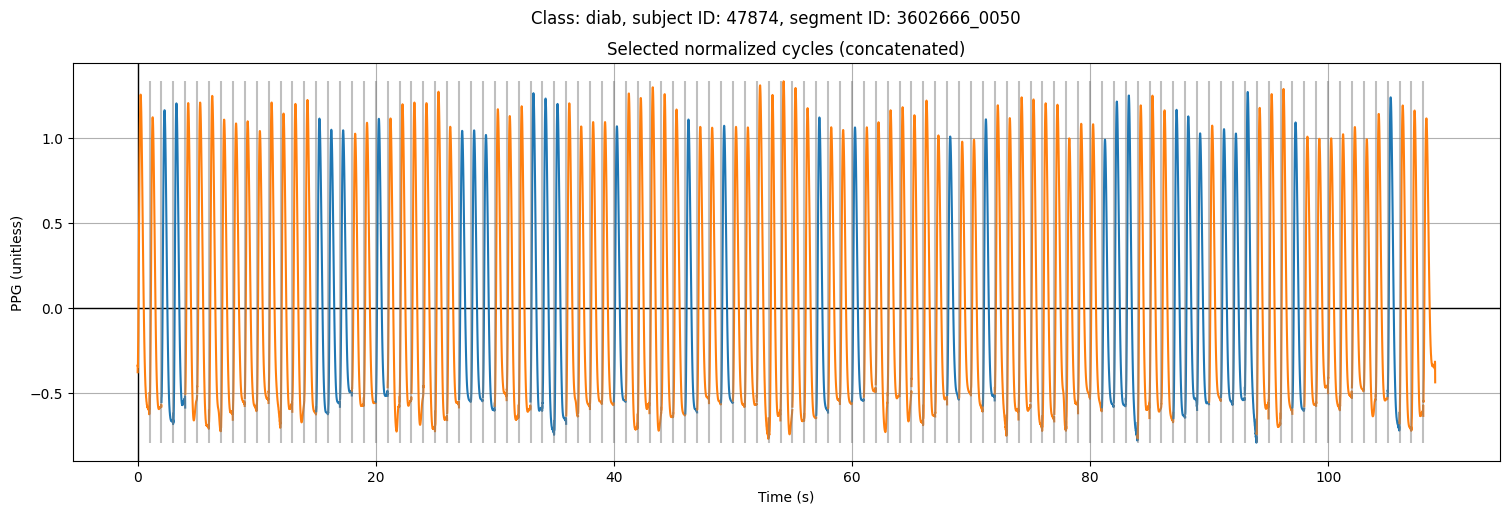

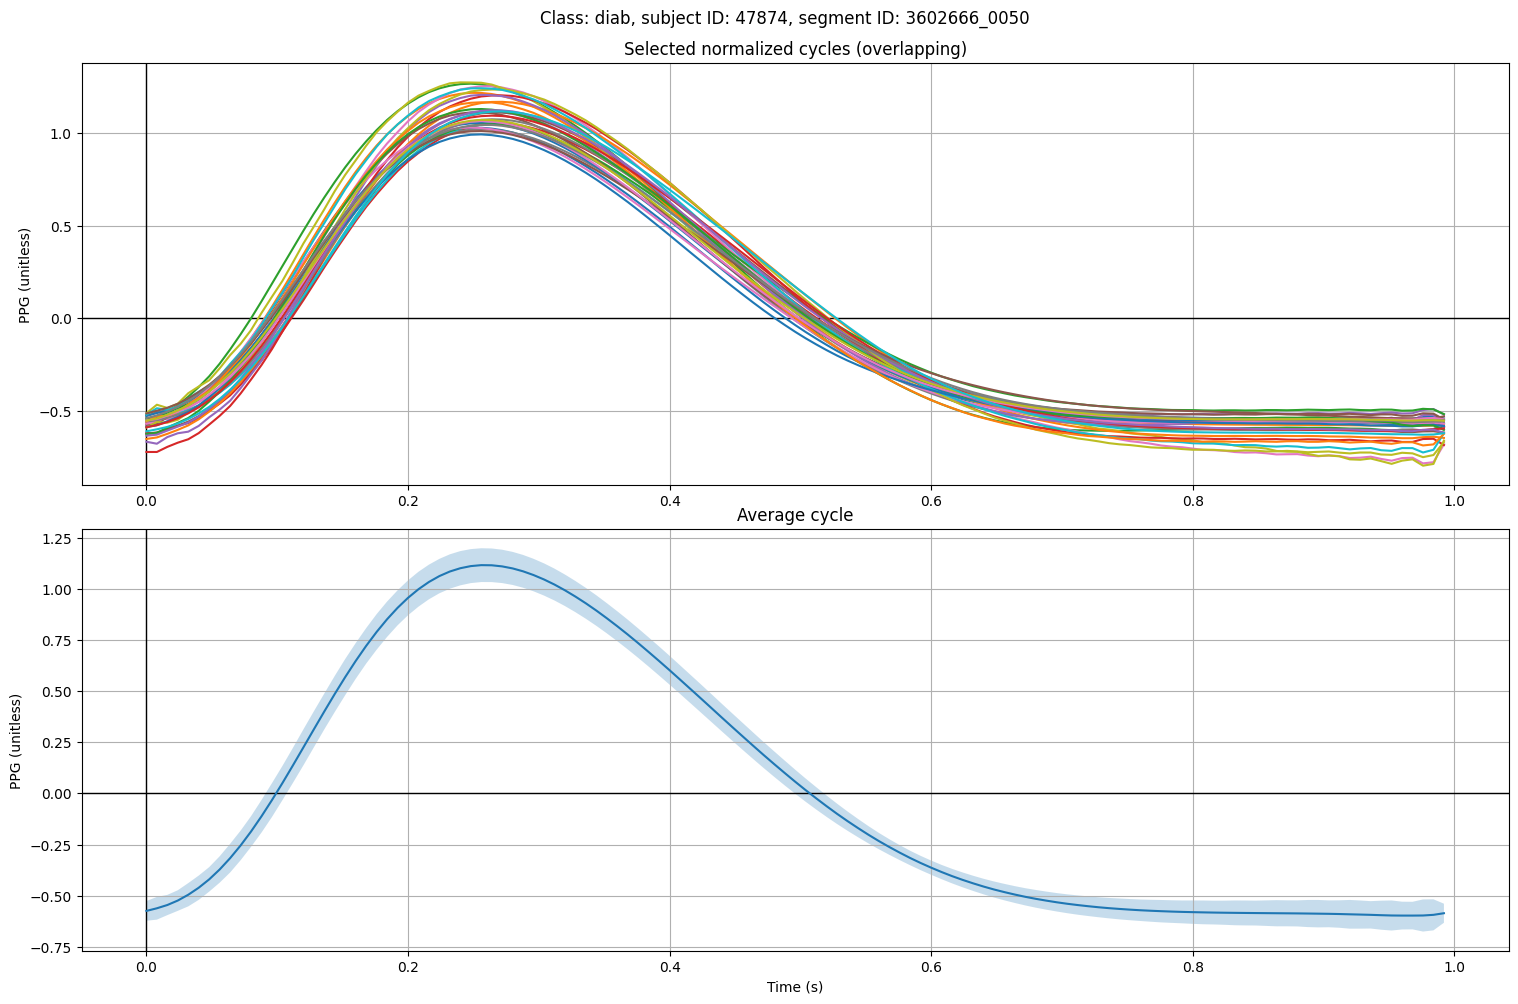

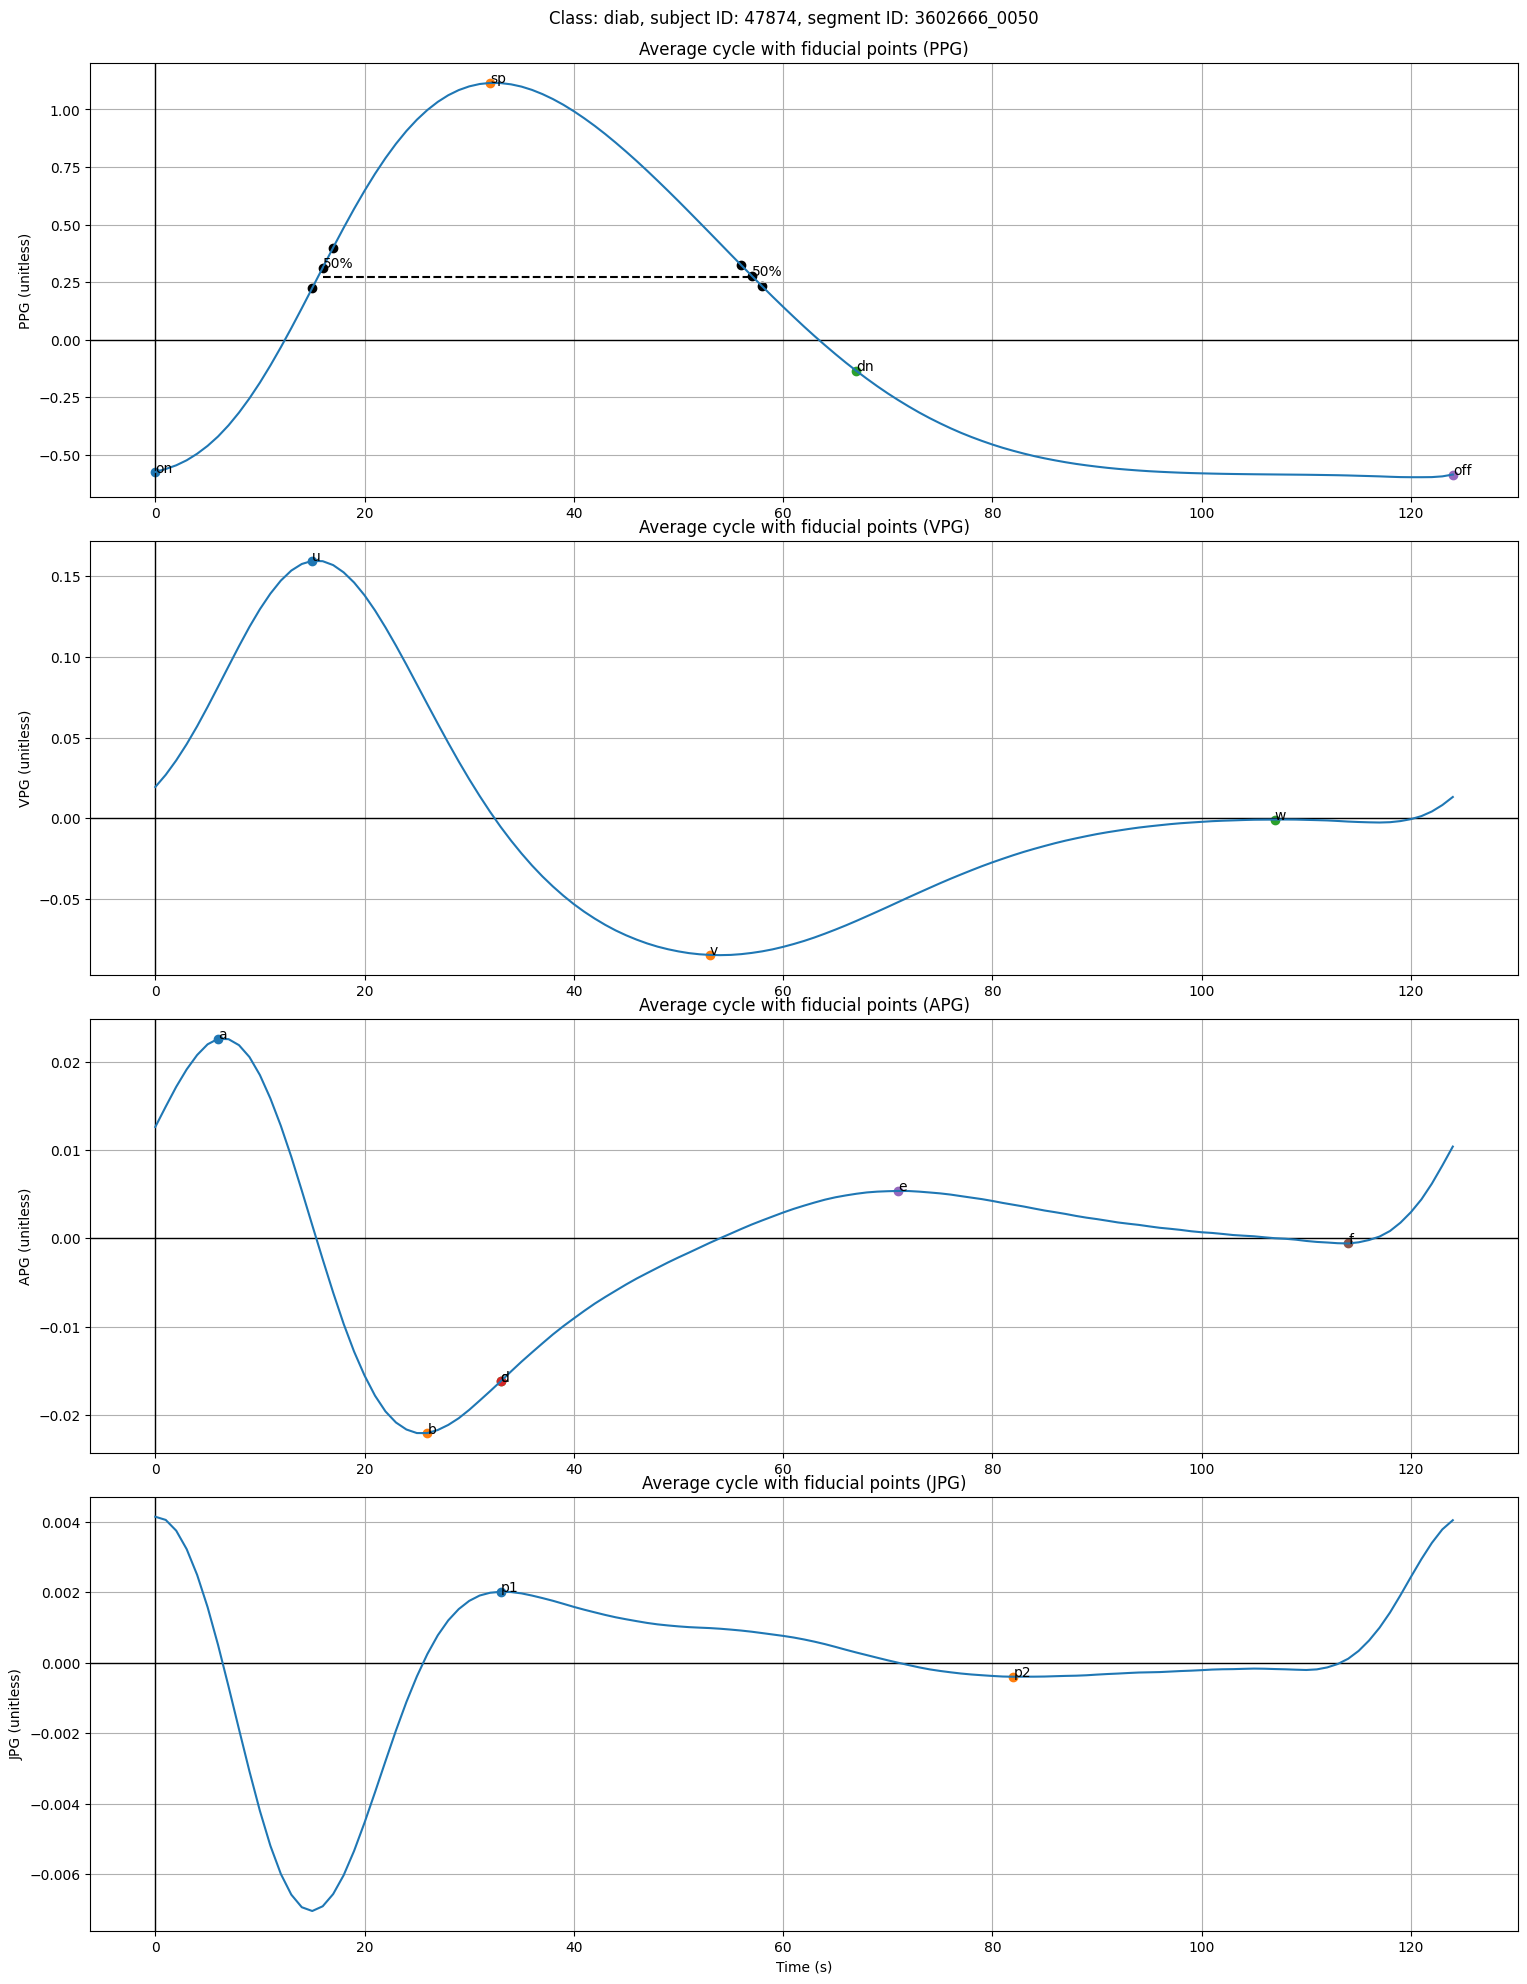

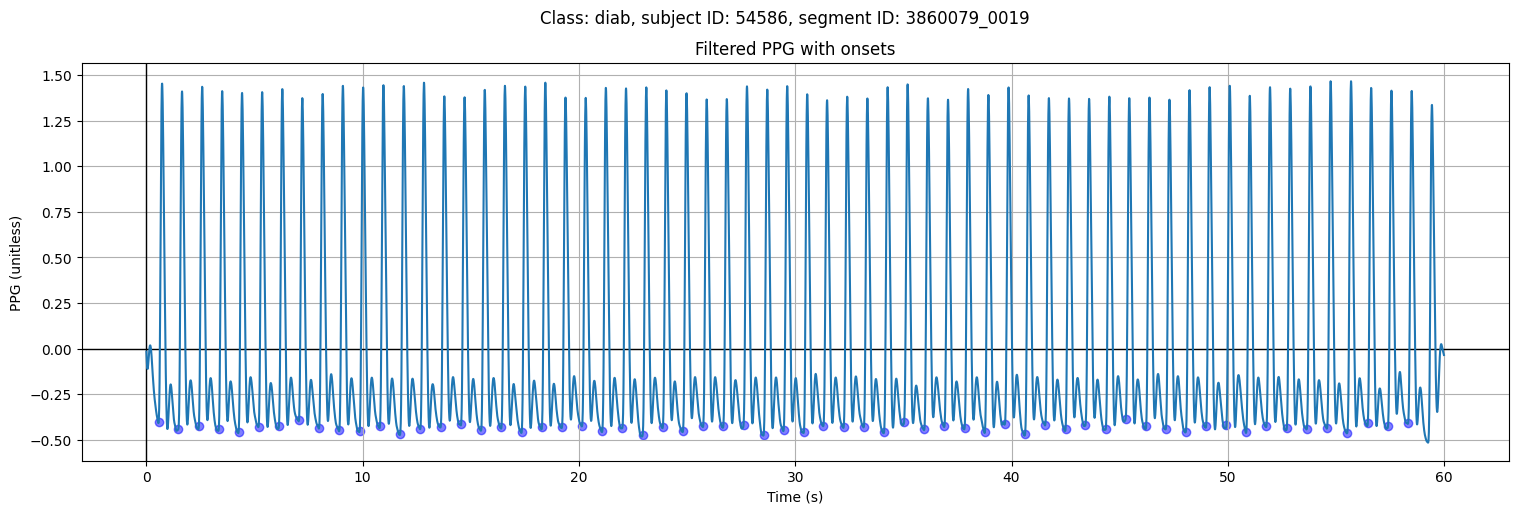

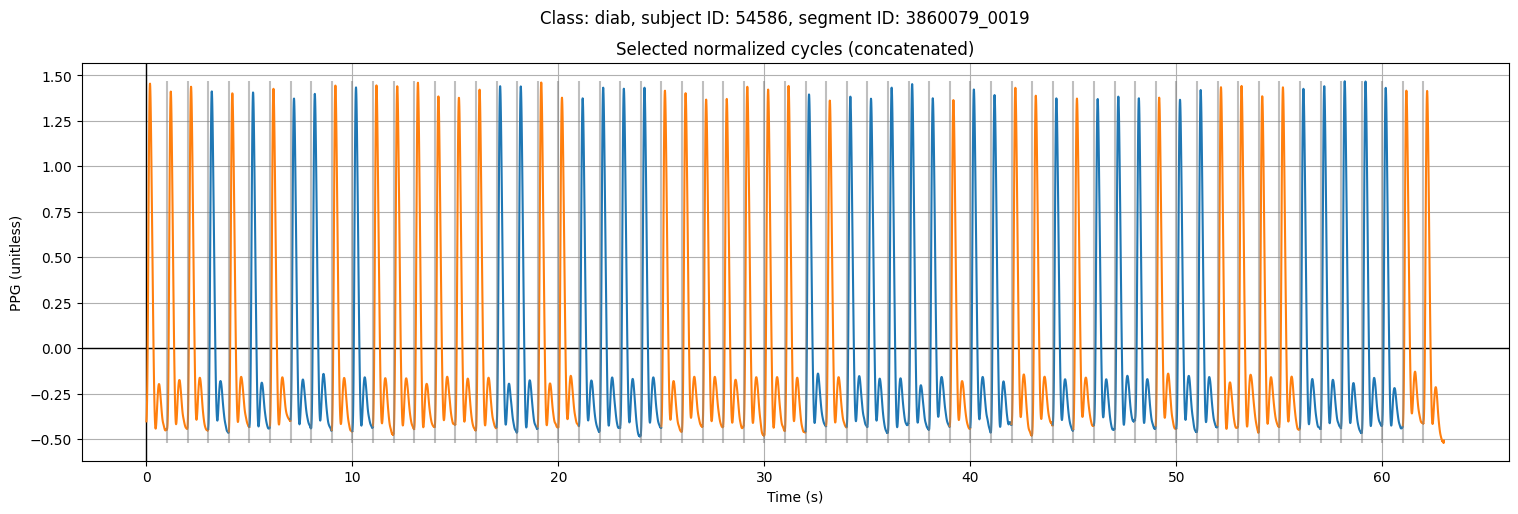

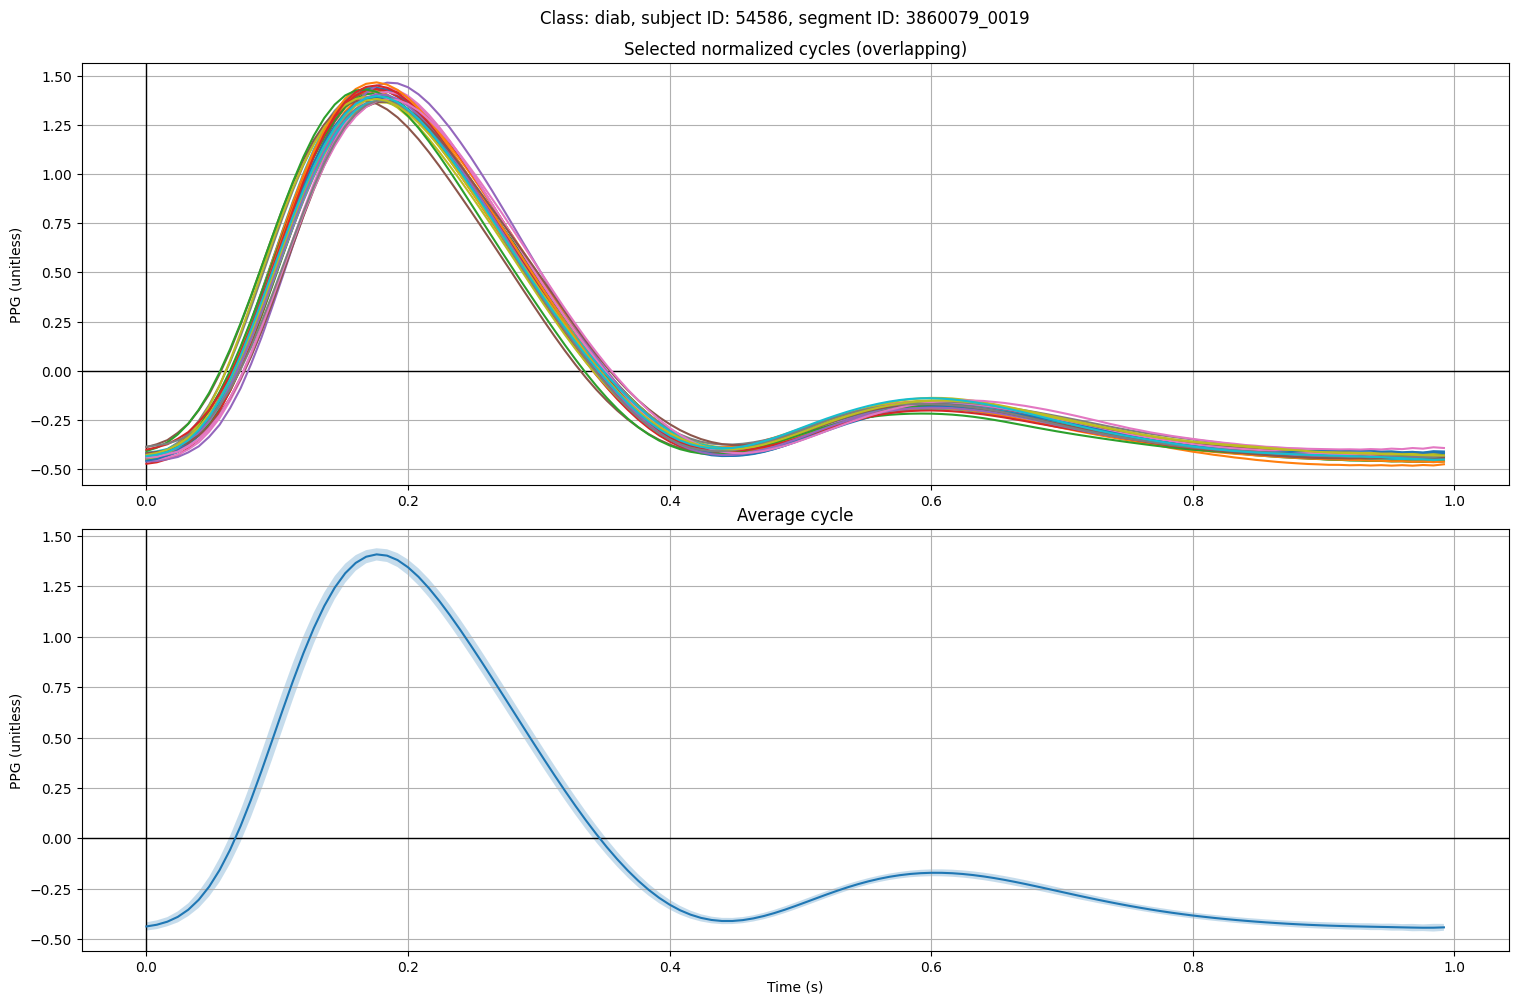

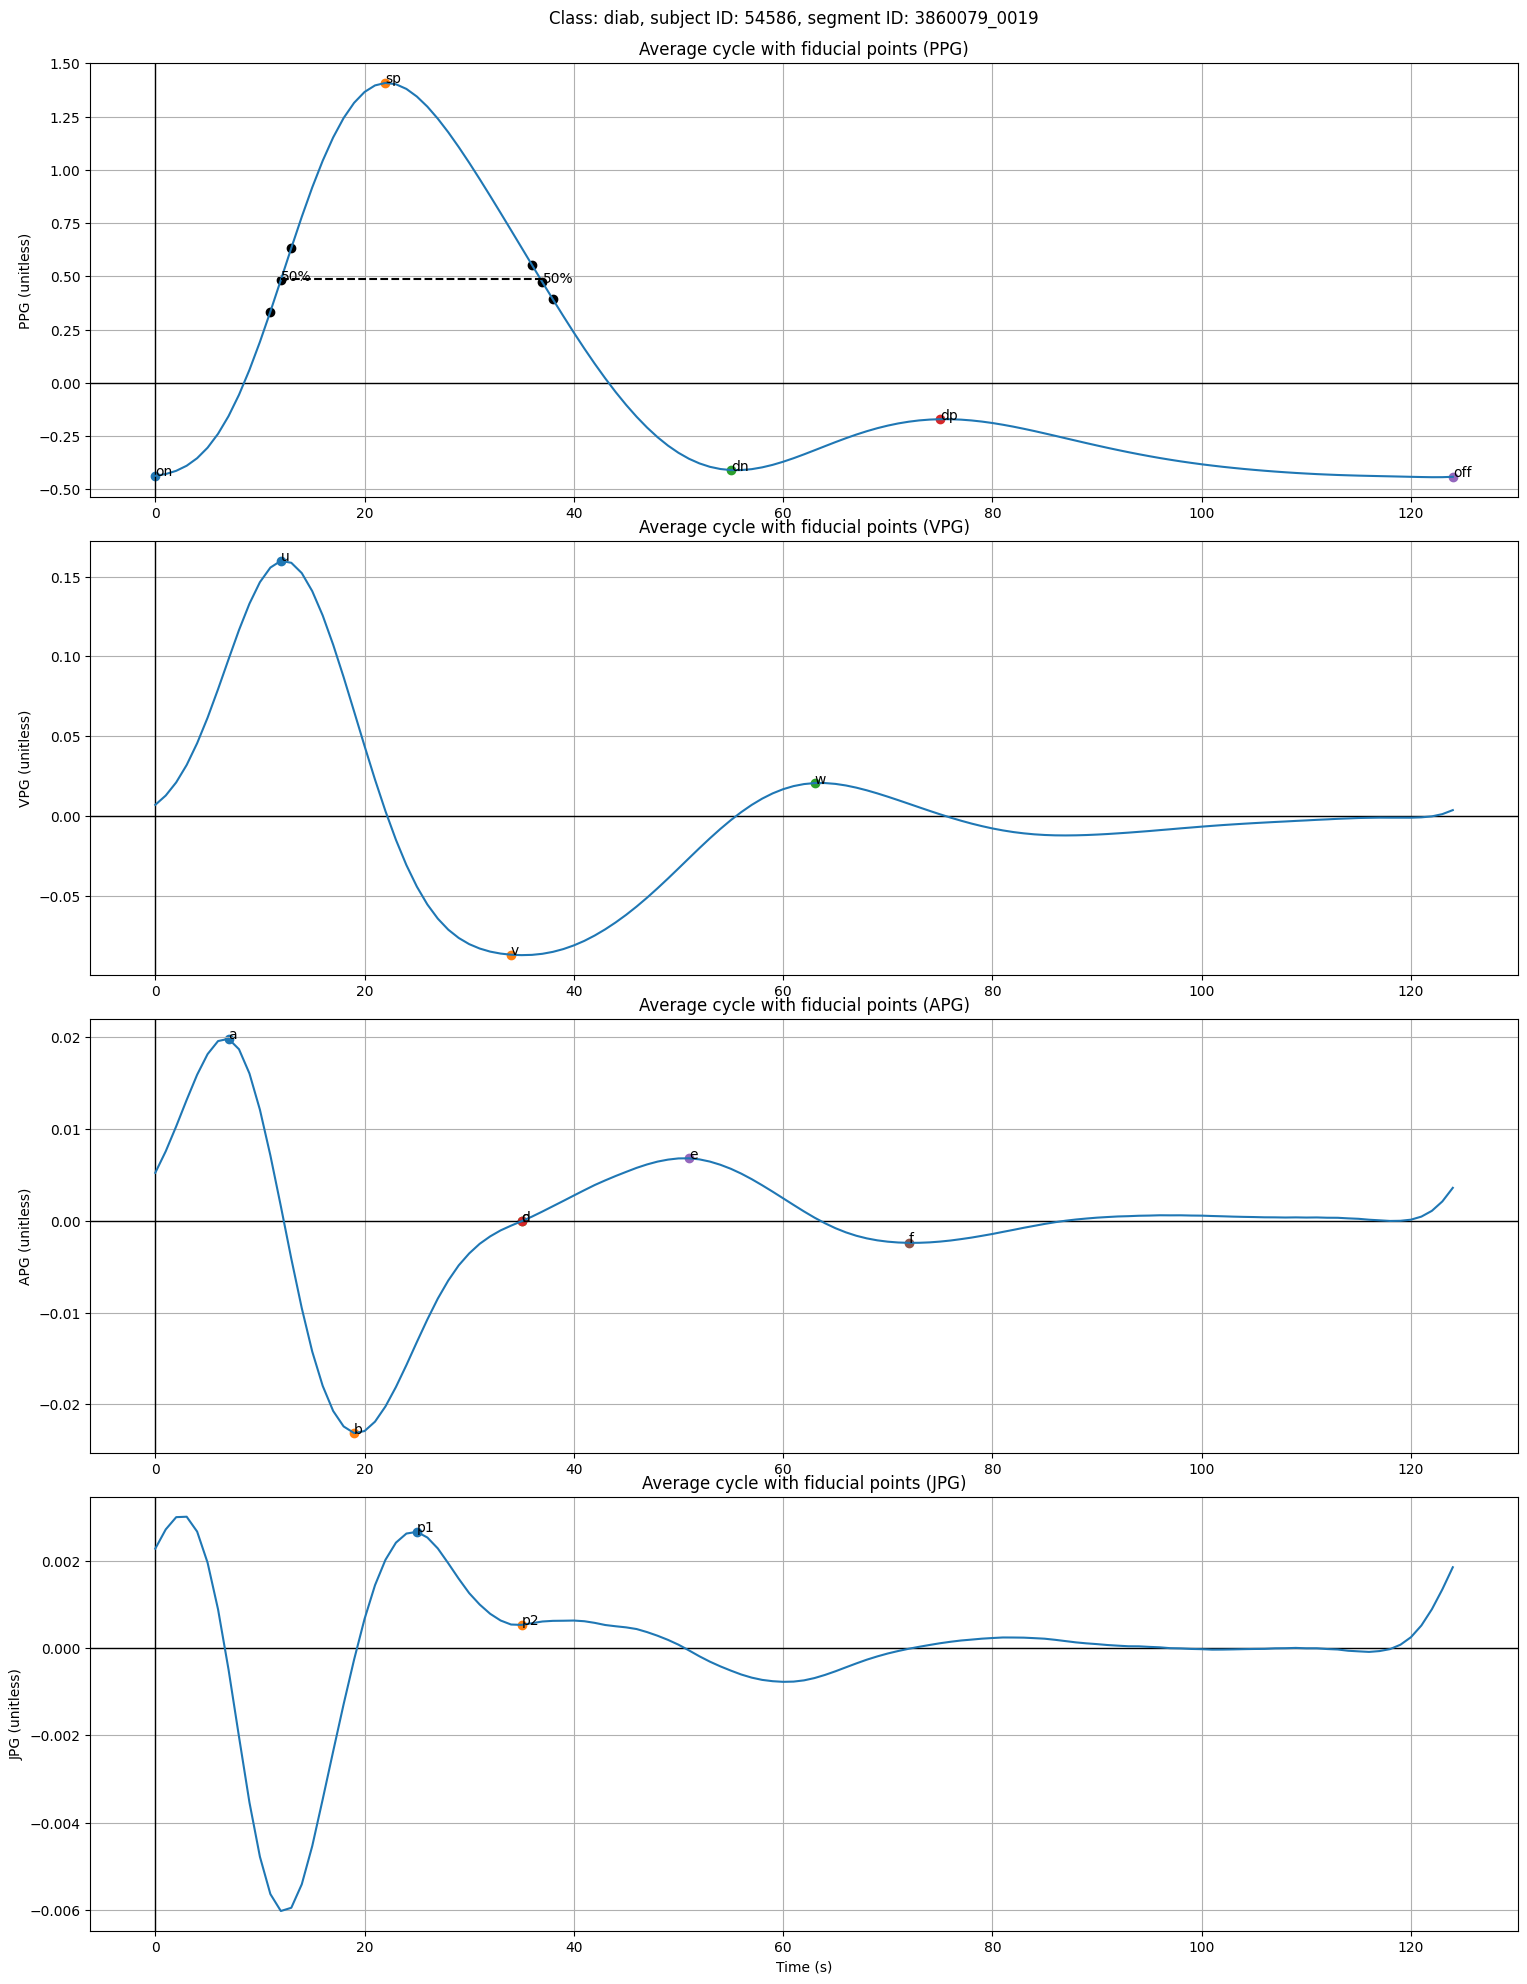

In [5]:
indices = {}

subject_records = df_subjects[['subject_id', 'segment_id', 'class']].itertuples(index=False)

for subject_id, segment_id, category in tqdm(subject_records):

    if subject_id not in [67763, 54586, 47874, 93566, 64485, 76237, 83263]:
    # if subject_id not in [64485, 54586]:
    # if subject_id not in [83263]:
        continue

    # setup signal and annotations

    t, ppg_raw = ppg_funcs.load_ppg(subject_id, segment_id)

    ppg, vpg, apg, jpg = ppg_funcs.preprocess_ppg(ppg_raw)

    peaks, onsets, cycles = ppg_funcs.get_peaks_and_onsets(df_points, subject_id)

    # setup figures

    fig_s, axes_s = plt.subplots(nrows=1, ncols=1, figsize=(15, 5))
    axes_s: plt.Axes
    fig_s.suptitle(f'Class: {category}, subject ID: {subject_id}, segment ID: {segment_id}')
    fig_s.tight_layout(rect=[0, 0, 1, 0.98])

    fig_r, axes_r = plt.subplots(nrows=1, ncols=1, figsize=(15, 5))
    axes_r: plt.Axes
    fig_r.suptitle(f'Class: {category}, subject ID: {subject_id}, segment ID: {segment_id}')
    fig_r.tight_layout(rect=[0, 0, 1, 0.98])

    fig_c, axes_c = plt.subplots(nrows=2, ncols=1, figsize=(15, 10))
    axes_c: tuple[plt.Axes]
    fig_c.suptitle(f'Class: {category}, subject ID: {subject_id}, segment ID: {segment_id}')
    fig_c.tight_layout(rect=[0, 0, 1, 0.98])

    fig_d, axes_d = plt.subplots(nrows=4, ncols=1, figsize=(15, 20))
    axes_d: tuple[plt.Axes]
    fig_d.suptitle(f'Class: {category}, subject ID: {subject_id}, segment ID: {segment_id}')
    fig_d.tight_layout(rect=[0, 0, 1, 0.98])

    # setup axis lines

    for ax in [axes_s, axes_r, *axes_c, *axes_d]:
        ax.axhline(color='black', linewidth=1)
        ax.axvline(color='black', linewidth=1)

    # plot filtered signal

    axes_s.plot(t, ppg)
    axes_s.scatter(t[cycles[:, 0]], ppg[cycles[:, 0]], color='blue', alpha=0.5)
    axes_s.set_title('Filtered PPG with onsets')
    axes_s.set_xlabel('Time (s)')
    axes_s.set_ylabel('PPG (unitless)')
    axes_s.grid()

    # normalize and filter cycles

    normalized_signals, normalized_peaks = ppg_funcs.normalize_cycles(ppg, vpg, apg, jpg, peaks, cycles)
    ppg_norm_cycle_signals, vpg_norm_cycle_signals, apg_norm_cycle_signals, jpg_norm_cycle_signals = normalized_signals
    ppg_norm_cycle_peaks = normalized_peaks

    selected_indices, selected_mask = ppg_funcs.select_cycles(ppg_norm_cycle_signals, ppg_norm_cycle_peaks)

    # plot selected normalized cycles

    num_cycles = ppg_norm_cycle_signals.shape[0]
    for k, (signal, selected) in enumerate(zip(ppg_norm_cycle_signals, selected_mask)):
        time = np.linspace(k, (k + 1) - 1 / c.SIGNAL_FS, c.SIGNAL_FS)
        axes_r.plot(time, signal, color='C0' if selected else 'C1')
    axes_r.vlines(np.arange(1, num_cycles, 1), np.min(ppg_norm_cycle_signals), np.max(ppg_norm_cycle_signals), color='grey', alpha=0.5)
    axes_r.set_title('Selected normalized cycles (concatenated)')
    axes_r.set_xlabel('Time (s)')
    axes_r.set_ylabel('PPG (unitless)')
    axes_r.grid()

    cycle_signal_time = np.linspace(0, 1 - 1 / c.SIGNAL_FS, c.SIGNAL_FS)

    for signal in ppg_norm_cycle_signals[selected_indices]:
        axes_c[0].plot(cycle_signal_time, signal)
    axes_c[0].set_title('Selected normalized cycles (overlapping)')
    axes_c[0].set_ylabel('PPG (unitless)')
    axes_c[0].grid()

    # average cycle

    ppg_avg = np.mean(ppg_norm_cycle_signals[selected_indices], axis=0)
    ppg_std = np.std(ppg_norm_cycle_signals[selected_indices], axis=0)

    vpg_avg = np.mean(vpg_norm_cycle_signals[selected_indices], axis=0)

    apg_avg = np.mean(apg_norm_cycle_signals[selected_indices], axis=0)

    jpg_avg = np.mean(jpg_norm_cycle_signals[selected_indices], axis=0)

    # plot average cycle

    axes_c[1].plot(cycle_signal_time, ppg_avg)
    axes_c[1].fill_between(cycle_signal_time, ppg_avg - ppg_std, ppg_avg + ppg_std, alpha=0.25)
    # axes_c[1].errorbar(cycle_signal_time, ppg_avg, ppg_std)
    axes_c[1].set_title('Average cycle')
    axes_c[1].set_xlabel('Time (s)')
    axes_c[1].set_ylabel('PPG (unitless)')
    axes_c[1].grid()

    # get fiducial points

    ppg_avg_peak = np.argmax(ppg_avg)
    ppg_avg_peaks = np.array([ppg_avg_peak, ppg_avg_peak + 125])
    ppg_avg_onsets = np.array([0, 124])

    df_fps = ppg_funcs.get_fiducial_points(ppg_avg, vpg_avg, apg_avg, jpg_avg, peaks=ppg_avg_peaks, onsets=ppg_avg_onsets)

    s_fps = df_fps.squeeze()

    ppg_fps = s_fps[['on', 'sp', 'dn', 'dp', 'off']]
    vpg_fps = s_fps[['u', 'v', 'w']]
    apg_fps = s_fps[['a', 'b', 'c', 'd', 'e', 'f']] + 1
    jpg_fps = s_fps[['p1', 'p2']] + 1

    # plot fiducial points

    names = ['PPG', 'VPG', 'APG', 'JPG']
    signals = [ppg_avg, vpg_avg, apg_avg, jpg_avg]
    point_sets = [ppg_fps, vpg_fps, apg_fps, jpg_fps]
    for ax, name, signal, s_points in zip(axes_d, names, signals, point_sets):
        ax.plot(signal)
        for k, (l, t_p) in enumerate(s_points.items()):
            if not pd.isna(t_p):
                ax.scatter(t_p, signal[t_p], color=f'C{k}')
                ax.annotate(l, (t_p, signal[t_p]))
        ax.set_title(f'Average cycle with fiducial points ({name})')
        if name == 'JPG':
            ax.set_xlabel('Time (s)')
        ax.set_ylabel(f'{name} (unitless)')
        ax.grid()

    # save figures

    # fig_s.savefig(f'images/doc/{subject_id}_signal.png')
    # fig_r.savefig(f'images/doc/{subject_id}_resampled.png')
    # fig_c.savefig(f'images/doc/{subject_id}_cycle.png')
    # fig_d.savefig(f'images/doc/{subject_id}_points.pdf')

    # calculate indices

    s_indices = ppg_funcs.calc_indices(ppg_avg, vpg_avg, apg_avg, jpg_avg, s_fps, return_all=True)

    indices[subject_id] = s_indices

    # plot some indices

    s_50 = s_indices['s_50']
    t_50_rise = int(s_indices['t_50_rise'])
    t_50_fall = int(s_indices['t_50_fall'])

    axes_d[0].hlines(s_50, t_50_rise, t_50_fall, color='black', linestyles='dashed')

    # axes_d[0].scatter(t_50_rise, s.ppg_avg[t_50_rise], color='black')
    axes_d[0].scatter([t_50_rise-1, t_50_rise, t_50_rise+1], [ppg_avg[t_50_rise-1], ppg_avg[t_50_rise], ppg_avg[t_50_rise+1]], color='black')
    axes_d[0].annotate('50%', (t_50_rise, ppg_avg[t_50_rise]))

    # axes_d[0].scatter(t_50_fall, s.ppg_avg[t_50_fall], color='black')
    axes_d[0].scatter([t_50_fall-1, t_50_fall, t_50_fall+1], [ppg_avg[t_50_fall-1], ppg_avg[t_50_fall], ppg_avg[t_50_fall+1]], color='black')
    axes_d[0].annotate('50%', (t_50_fall, ppg_avg[t_50_fall]))

In [6]:
indices = {}

subject_records = df_subjects[['subject_id', 'segment_id', 'class']].itertuples(index=False)

for subject_id, segment_id, category in tqdm(subject_records):

    # setup signal and annotations
    t, ppg_raw = ppg_funcs.load_ppg(subject_id, segment_id)
    ppg, vpg, apg, jpg = ppg_funcs.preprocess_ppg(ppg_raw)
    peaks, onsets, cycles = ppg_funcs.get_peaks_and_onsets(df_points, subject_id)

    # normalize and filter cycles
    normalized_signals, normalized_peaks = ppg_funcs.normalize_cycles(ppg, vpg, apg, jpg, peaks, cycles)
    ppg_norm_cycle_signals, vpg_norm_cycle_signals, apg_norm_cycle_signals, jpg_norm_cycle_signals = normalized_signals
    ppg_norm_cycle_peaks = normalized_peaks
    selected_indices, selected_mask = ppg_funcs.select_cycles(ppg_norm_cycle_signals, ppg_norm_cycle_peaks)

    # average cycle
    ppg_avg = np.mean(ppg_norm_cycle_signals[selected_indices], axis=0)
    vpg_avg = np.mean(vpg_norm_cycle_signals[selected_indices], axis=0)
    apg_avg = np.mean(apg_norm_cycle_signals[selected_indices], axis=0)
    jpg_avg = np.mean(jpg_norm_cycle_signals[selected_indices], axis=0)
    ppg_std = np.std(ppg_norm_cycle_signals[selected_indices], axis=0)

    # get fiducial points
    ppg_avg_peak = np.argmax(ppg_avg)
    ppg_avg_peaks = np.array([ppg_avg_peak, ppg_avg_peak + 125])
    ppg_avg_onsets = np.array([0, 124])
    df_fps = ppg_funcs.get_fiducial_points(ppg_avg, vpg_avg, apg_avg, jpg_avg, peaks=ppg_avg_peaks, onsets=ppg_avg_onsets)
    s_fps = df_fps.squeeze()
    s_fps[['a', 'b', 'c', 'd', 'e', 'f']] += 1
    s_fps[['p1', 'p2']] += 1

    # calculate indices
    s_indices = ppg_funcs.calc_indices(ppg_avg, vpg_avg, apg_avg, jpg_avg, s_fps)
    indices[subject_id] = s_indices

df_indices = pd.DataFrame(indices).T.reset_index(names='subject_id')
df_indices

34it [00:04,  8.44it/s]


,subject_id,a_s,a_d,t_pw,ri,ai,t_dt,t_ct,r_b_a,r_c_a,r_d_a,r_e_a,r_b_c_d_e_a,r_b_e_a,r_b_c_d_a
0,48480,0.361873,0.031386,38.0,0.086732,0.913268,59.0,32.0,-1.085609,-0.567642,-0.567642,0.317664,-0.267990,-1.403273,0.049674
1,63646,1.491539,0.779208,45.0,0.522419,0.477581,25.0,36.0,-0.781589,-0.715132,-0.715132,0.242890,0.405785,-1.024479,0.648675
2,64485,0.089306,0.064812,68.0,0.725731,0.274269,27.0,41.0,-0.705074,-0.270410,-0.280023,0.079289,-0.233929,-0.784363,-0.154641
3,64916,1.894331,1.072385,37.0,0.566102,0.433898,18.0,31.0,-0.702971,-0.560234,-0.660374,0.301680,0.215957,-1.004651,0.517637
4,66682,1.816996,0.193730,40.0,0.106621,0.893379,64.0,28.0,-0.914228,-0.105199,-0.105199,0.229847,-0.933677,-1.144075,-0.703830
5,67763,1.796338,0.200030,33.0,0.111354,0.888646,55.0,26.0,-1.079361,-0.023074,-0.023074,0.331617,-1.364831,-1.410978,-1.033214
6,69006,1.831890,0.936452,44.0,0.511194,0.488806,23.0,36.0,-0.713629,-0.586352,-0.668427,0.328535,0.212616,-1.042164,0.541151
7,76178,0.225135,0.092970,48.0,0.412953,0.587047,40.0,31.0,-0.851224,-0.339708,-0.339708,0.215687,-0.387496,-1.066911,-0.171809
8,76237,1.769964,-0.017138,34.0,-0.009683,1.009683,59.0,24.0,-1.084380,-0.066254,-0.066254,0.230860,-1.182733,-1.315240,-0.951873
9,81633,0.621320,0.576498,78.0,0.927859,0.072141,14.0,43.0,-0.475720,-0.175553,-0.322554,0.023879,-0.001493,-0.499599,0.022386


In [7]:
df_indices.to_csv(c.CSV_DIR / 'features_ecg.csv', index=False)

In [8]:
df = df_subjects[['subject_id', 'class']].merge(df_indices, on='subject_id').set_index('subject_id')
df

,class,a_s,a_d,t_pw,ri,ai,t_dt,t_ct,r_b_a,r_c_a,r_d_a,r_e_a,r_b_c_d_e_a,r_b_e_a,r_b_c_d_a
subject_id,,,,,,,,,,,,,,,
48480,control,0.361873,0.031386,38.0,0.086732,0.913268,59.0,32.0,-1.085609,-0.567642,-0.567642,0.317664,-0.267990,-1.403273,0.049674
63646,control,1.491539,0.779208,45.0,0.522419,0.477581,25.0,36.0,-0.781589,-0.715132,-0.715132,0.242890,0.405785,-1.024479,0.648675
64485,control,0.089306,0.064812,68.0,0.725731,0.274269,27.0,41.0,-0.705074,-0.270410,-0.280023,0.079289,-0.233929,-0.784363,-0.154641
64916,control,1.894331,1.072385,37.0,0.566102,0.433898,18.0,31.0,-0.702971,-0.560234,-0.660374,0.301680,0.215957,-1.004651,0.517637
66682,control,1.816996,0.193730,40.0,0.106621,0.893379,64.0,28.0,-0.914228,-0.105199,-0.105199,0.229847,-0.933677,-1.144075,-0.703830
67763,control,1.796338,0.200030,33.0,0.111354,0.888646,55.0,26.0,-1.079361,-0.023074,-0.023074,0.331617,-1.364831,-1.410978,-1.033214
69006,control,1.831890,0.936452,44.0,0.511194,0.488806,23.0,36.0,-0.713629,-0.586352,-0.668427,0.328535,0.212616,-1.042164,0.541151
76178,control,0.225135,0.092970,48.0,0.412953,0.587047,40.0,31.0,-0.851224,-0.339708,-0.339708,0.215687,-0.387496,-1.066911,-0.171809
76237,control,1.769964,-0.017138,34.0,-0.009683,1.009683,59.0,24.0,-1.084380,-0.066254,-0.066254,0.230860,-1.182733,-1.315240,-0.951873


In [9]:
df.replace({'control': 0, 'diab': 1}).infer_objects(copy=False)

/tmp/ipykernel_95752/4260507598.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.replace({'control': 0, 'diab': 1}).infer_objects(copy=False)


,class,a_s,a_d,t_pw,ri,ai,t_dt,t_ct,r_b_a,r_c_a,r_d_a,r_e_a,r_b_c_d_e_a,r_b_e_a,r_b_c_d_a
subject_id,,,,,,,,,,,,,,,
48480,0,0.361873,0.031386,38.0,0.086732,0.913268,59.0,32.0,-1.085609,-0.567642,-0.567642,0.317664,-0.267990,-1.403273,0.049674
63646,0,1.491539,0.779208,45.0,0.522419,0.477581,25.0,36.0,-0.781589,-0.715132,-0.715132,0.242890,0.405785,-1.024479,0.648675
64485,0,0.089306,0.064812,68.0,0.725731,0.274269,27.0,41.0,-0.705074,-0.270410,-0.280023,0.079289,-0.233929,-0.784363,-0.154641
64916,0,1.894331,1.072385,37.0,0.566102,0.433898,18.0,31.0,-0.702971,-0.560234,-0.660374,0.301680,0.215957,-1.004651,0.517637
66682,0,1.816996,0.193730,40.0,0.106621,0.893379,64.0,28.0,-0.914228,-0.105199,-0.105199,0.229847,-0.933677,-1.144075,-0.703830
67763,0,1.796338,0.200030,33.0,0.111354,0.888646,55.0,26.0,-1.079361,-0.023074,-0.023074,0.331617,-1.364831,-1.410978,-1.033214
69006,0,1.831890,0.936452,44.0,0.511194,0.488806,23.0,36.0,-0.713629,-0.586352,-0.668427,0.328535,0.212616,-1.042164,0.541151
76178,0,0.225135,0.092970,48.0,0.412953,0.587047,40.0,31.0,-0.851224,-0.339708,-0.339708,0.215687,-0.387496,-1.066911,-0.171809
76237,0,1.769964,-0.017138,34.0,-0.009683,1.009683,59.0,24.0,-1.084380,-0.066254,-0.066254,0.230860,-1.182733,-1.315240,-0.951873


In [10]:
df.replace({'control': 0, 'diab': 1}).corr()

/tmp/ipykernel_95752/764933252.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.replace({'control': 0, 'diab': 1}).corr()


,class,a_s,a_d,t_pw,ri,ai,t_dt,t_ct,r_b_a,r_c_a,r_d_a,r_e_a,r_b_c_d_e_a,r_b_e_a,r_b_c_d_a
class,1.000000,0.046495,-0.096706,-0.305354,-0.203800,0.203800,0.046697,-0.299575,-0.154485,0.267408,0.237651,0.318905,-0.319945,-0.256853,-0.267140
a_s,0.046495,1.000000,0.573164,-0.389909,-0.269749,0.269749,0.053860,-0.221038,-0.234455,0.111343,0.097276,0.219632,-0.206468,-0.264073,-0.169066
a_d,-0.096706,0.573164,1.000000,0.166264,0.514127,-0.514127,-0.678286,0.299450,0.304716,-0.214911,-0.275584,-0.144481,0.322825,0.276158,0.312166
t_pw,-0.305354,-0.389909,0.166264,1.000000,0.803132,-0.803132,-0.512342,0.739747,0.667332,-0.003337,-0.064324,-0.612942,0.377140,0.745832,0.257913
ri,-0.203800,-0.269749,0.514127,0.803132,1.000000,-1.000000,-0.847994,0.639364,0.608862,-0.141117,-0.186490,-0.593665,0.456601,0.696860,0.347934
ai,0.203800,0.269749,-0.514127,-0.803132,-1.000000,1.000000,0.847994,-0.639364,-0.608862,0.141117,0.186490,0.593665,-0.456601,-0.696860,-0.347934
t_dt,0.046697,0.053860,-0.678286,-0.512342,-0.847994,0.847994,1.000000,-0.523322,-0.563559,0.268979,0.348747,0.399775,-0.512845,-0.573796,-0.454984
t_ct,-0.299575,-0.221038,0.299450,0.739747,0.639364,-0.639364,-0.523322,1.000000,0.720779,-0.362957,-0.374951,-0.402176,0.611417,0.681965,0.560330
r_b_a,-0.154485,-0.234455,0.304716,0.667332,0.608862,-0.608862,-0.563559,0.720779,1.000000,-0.263641,-0.348700,-0.479213,0.668209,0.908687,0.602838
r_c_a,0.267408,0.111343,-0.214911,-0.003337,-0.141117,0.141117,0.268979,-0.362957,-0.263641,1.000000,0.962614,0.060503,-0.871378,-0.208252,-0.921816


/tmp/ipykernel_95752/14483025.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  plt.matshow(df.replace({'control': 0, 'diab': 1}).corr())


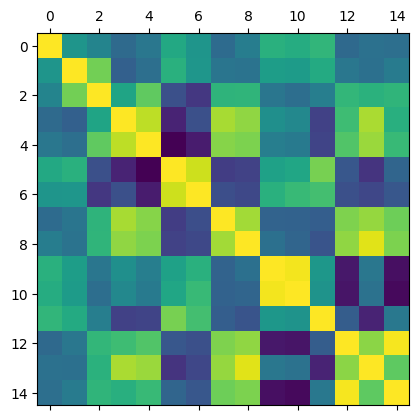

In [11]:
plt.matshow(df.replace({'control': 0, 'diab': 1}).corr())

/tmp/ipykernel_95752/3432336387.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  corr = df.replace({'control': 0, 'diab': 1}).infer_objects(copy=False).corr()


<Axes: >

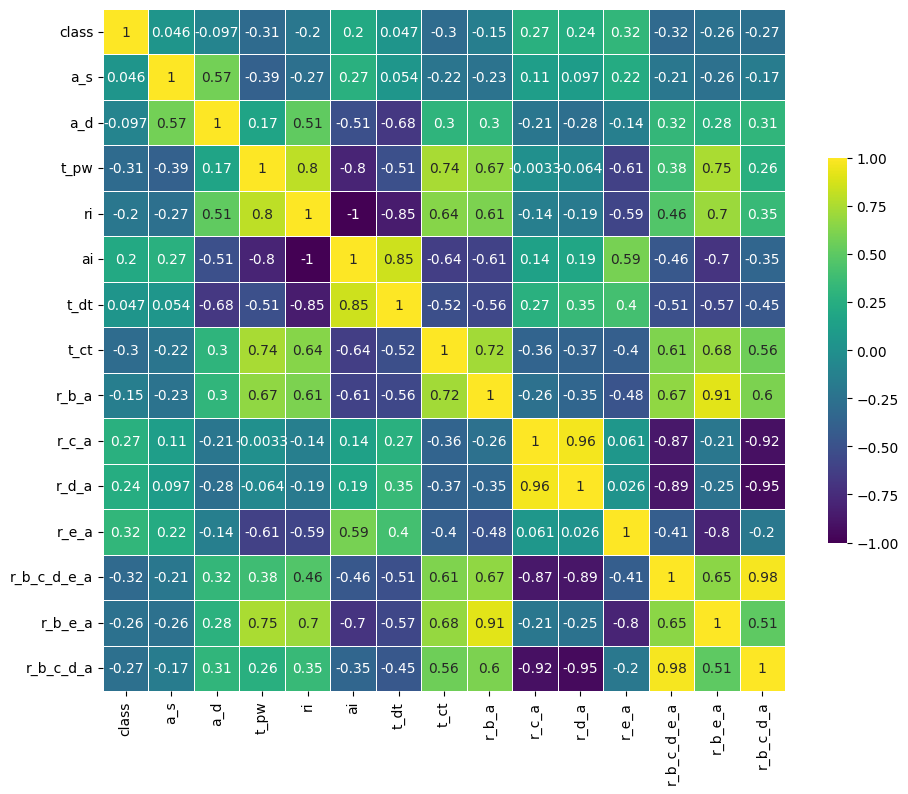

In [12]:
corr = df.replace({'control': 0, 'diab': 1}).infer_objects(copy=False).corr()
fig, ax = plt.subplots(figsize=(11, 10))
cmap = 'viridis'
# mask = np.triu(np.ones_like(corr, dtype=bool))
# sns.heatmap(corr, mask=mask, cmap=cmap, center=0, annot=True, square=True, linewidths=.5, cbar_kws={"shrink": .5})
sns.heatmap(corr, cmap=cmap, center=0, annot=True, square=True, linewidths=.5, cbar_kws={"shrink": .5})